# NLP Tutorial - All 15 ML Practicals

Run **Runtime > Run all** in Google Colab (CPU). Each practical resets its random seed. Teaching data are explicitly identified; saved outputs were generated by real local Python execution. All text datasets are embedded, so no Drive mount or private file is required.

In [ ]:
# Colab CPU runtime is sufficient. No external dataset download is needed.
%pip -q install 'scikit-learn>=1.5,<2' 'pandas>=2.2,<4' 'matplotlib>=3.8,<4'


## Practical 01: House Price Prediction

### Aim
Predict house prices using area, bedrooms, bathrooms, age and location features.

### Model
Linear Regression

### Data
800 generated houses. Area: square feet; age: years; price: INR lakh. Location has three categories.

### Theory
Linear regression estimates coefficients by minimizing squared residuals. Categorical locations are one-hot encoded; numerical features are imputed and scaled using training data only.

### Method
Load or generate data, inspect features and labels, fit preprocessing on training data, train the required model, evaluate and visualize the output. See the implementation for the task-specific split.

### Limitation
Generated prices follow a near-linear rule; the score does not establish performance on real property transactions.

In [ ]:
"""Shared imports and evaluation; also embedded in every standalone notebook."""
import re
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split
from sklearn.pipeline import make_pipeline
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.impute import SimpleImputer
from sklearn.linear_model import LinearRegression, LogisticRegression
from sklearn.neighbors import KNeighborsClassifier
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import (RandomForestClassifier, RandomForestRegressor,
    IsolationForest, GradientBoostingRegressor, AdaBoostRegressor)
from sklearn.svm import SVC, LinearSVC
from sklearn.naive_bayes import MultinomialNB
from sklearn.feature_extraction.text import (TfidfVectorizer,
    CountVectorizer, ENGLISH_STOP_WORDS)
from sklearn.cluster import KMeans
from sklearn.decomposition import PCA
from sklearn.datasets import load_iris, load_breast_cancer, load_digits
from sklearn.dummy import DummyClassifier, DummyRegressor
from sklearn.metrics import (accuracy_score, f1_score, classification_report,
    ConfusionMatrixDisplay, mean_absolute_error, mean_squared_error,
    r2_score, silhouette_score, average_precision_score)
SEED = 42
rng = np.random.default_rng(SEED)
OUT = Path('outputs')
OUT.mkdir(exist_ok=True)
plt.rcParams.update({'figure.figsize': (7, 4), 'font.size': 10})

def plot_save(name):
    plt.tight_layout()
    plt.savefig(OUT / f'{name}.png', dpi=150, bbox_inches='tight')
    plt.show()
    plt.close()

def tabular_preprocessor(frame):
    numeric = frame.select_dtypes(include='number').columns.tolist()
    category = frame.select_dtypes(exclude='number').columns.tolist()
    return ColumnTransformer([
        ('numeric', make_pipeline(SimpleImputer(strategy='median'),
                                  StandardScaler()), numeric),
        ('category', make_pipeline(SimpleImputer(strategy='most_frequent'),
          OneHotEncoder(handle_unknown='ignore', sparse_output=False)), category)])

def evaluate(model, X, y, name, classification=True, chronological=False):
    # All fitted preprocessing stays inside the model pipeline.
    Xtr, Xte, ytr, yte = train_test_split(X, y, test_size=0.25,
        random_state=None if chronological else SEED,
        shuffle=not chronological,
        stratify=y if classification and not chronological else None)
    model.fit(Xtr, ytr)
    pred = model.predict(Xte)
    print(f'Train: {len(ytr)} | Test: {len(yte)} | Features: '
          f'{X.shape[1] if hasattr(X, "shape") and len(X.shape)>1 else "text"}')
    if classification:
        baseline = DummyClassifier(strategy='most_frequent').fit(Xtr, ytr)
        metrics = {'accuracy': accuracy_score(yte, pred),
                   'macro_f1': f1_score(yte, pred, average='macro'),
                   'baseline_accuracy': accuracy_score(yte, baseline.predict(Xte))}
        print(classification_report(yte, pred, digits=3, zero_division=0))
        ConfusionMatrixDisplay.from_predictions(yte, pred, cmap='Blues',
                                                colorbar=False)
        plt.title(name.replace('_', ' '))
        if any(len(str(v)) > 8 for v in np.unique(yte)):
            plt.xticks(rotation=30, ha='right')
    else:
        baseline = DummyRegressor().fit(Xtr, ytr)
        metrics = {'MAE': mean_absolute_error(yte, pred),
                   'RMSE': np.sqrt(mean_squared_error(yte, pred)),
                   'R2': r2_score(yte, pred),
                   'baseline_MAE': mean_absolute_error(yte, baseline.predict(Xte))}
        plt.scatter(yte, pred, alpha=0.6, s=18)
        lo, hi = min(min(yte), min(pred)), max(max(yte), max(pred))
        plt.plot([lo, hi], [lo, hi], 'k--')
        plt.xlabel('Actual target'); plt.ylabel('Predicted target')
        plt.title(name.replace('_', ' '))
    for key, value in metrics.items():
        print(f'{key}: {value:.4f}')
    plot_save(name)
    print('First five held-out predictions:', pred[:5])
    return metrics

def clean_text(text):
    text = re.sub(r'https?://\S+', ' url ', str(text).lower())
    text = re.sub(r'\d+', ' number ', text)
    return ' '.join(re.findall(r'[a-z]+', text))


In [ ]:
DATA = Path('data')
DATA.mkdir(exist_ok=True)


Train: 600 | Test: 200 | Features: 5
MAE: 5.9756
RMSE: 7.4847
R2: 0.9565
baseline_MAE: 29.8094


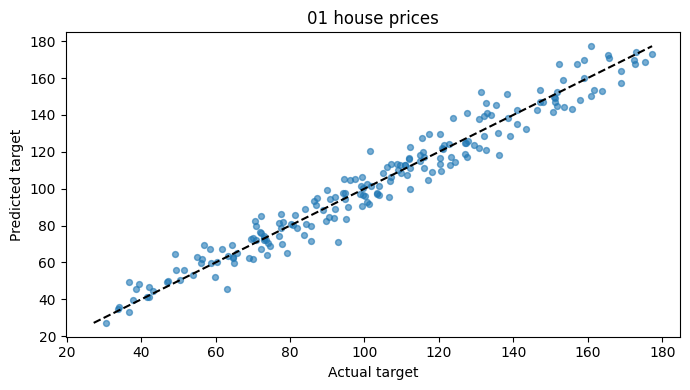

First five held-out predictions: [124.98477244 168.86948    122.60183702  83.96832199  89.14452053]


In [ ]:
n = 800
X = pd.DataFrame({'area': rng.uniform(500, 3500, n),
    'bedrooms': rng.integers(1, 6, n),
    'bathrooms': rng.integers(1, 5, n),
    'age': rng.integers(0, 41, n),
    'location': rng.choice(['central', 'suburb', 'outskirts'], n)})
premium = X.location.map({'central': 30, 'suburb': 15, 'outskirts': 0})
y = (0.035*X.area + 5*X.bedrooms + 4*X.bathrooms
     - 0.5*X.age + premium + rng.normal(0, 7, n))
model = make_pipeline(tabular_preprocessor(X), LinearRegression())
metrics = evaluate(model, X, y, '01_house_prices', classification=False)

### Result and conclusion
Measured results: MAE = 5.9756; RMSE = 7.4847; R2 = 0.9565; baseline_MAE = 29.8094. Generated prices follow a near-linear rule; the score does not establish performance on real property transactions.

## Practical 02: Loan Approval Prediction

### Aim
Predict approval from income, credit history, loan amount and employment information.

### Model
Logistic Regression

### Data
1,000 generated applications. Income and loan amount are in INR lakh; credit history is a binary indicator.

### Theory
Logistic regression maps a linear score to a probability using the sigmoid function. A stratified split preserves label proportions; scaling and employment encoding are fitted only on training rows.

### Method
Load or generate data, inspect features and labels, fit preprocessing on training data, train the required model, evaluate and visualize the output. See the implementation for the task-specific split.

### Limitation
The labels are simulated for teaching. Real lending requires representative data, policy checks and fairness evaluation.

In [ ]:
"""Shared imports and evaluation; also embedded in every standalone notebook."""
import re
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split
from sklearn.pipeline import make_pipeline
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.impute import SimpleImputer
from sklearn.linear_model import LinearRegression, LogisticRegression
from sklearn.neighbors import KNeighborsClassifier
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import (RandomForestClassifier, RandomForestRegressor,
    IsolationForest, GradientBoostingRegressor, AdaBoostRegressor)
from sklearn.svm import SVC, LinearSVC
from sklearn.naive_bayes import MultinomialNB
from sklearn.feature_extraction.text import (TfidfVectorizer,
    CountVectorizer, ENGLISH_STOP_WORDS)
from sklearn.cluster import KMeans
from sklearn.decomposition import PCA
from sklearn.datasets import load_iris, load_breast_cancer, load_digits
from sklearn.dummy import DummyClassifier, DummyRegressor
from sklearn.metrics import (accuracy_score, f1_score, classification_report,
    ConfusionMatrixDisplay, mean_absolute_error, mean_squared_error,
    r2_score, silhouette_score, average_precision_score)
SEED = 42
rng = np.random.default_rng(SEED)
OUT = Path('outputs')
OUT.mkdir(exist_ok=True)
plt.rcParams.update({'figure.figsize': (7, 4), 'font.size': 10})

def plot_save(name):
    plt.tight_layout()
    plt.savefig(OUT / f'{name}.png', dpi=150, bbox_inches='tight')
    plt.show()
    plt.close()

def tabular_preprocessor(frame):
    numeric = frame.select_dtypes(include='number').columns.tolist()
    category = frame.select_dtypes(exclude='number').columns.tolist()
    return ColumnTransformer([
        ('numeric', make_pipeline(SimpleImputer(strategy='median'),
                                  StandardScaler()), numeric),
        ('category', make_pipeline(SimpleImputer(strategy='most_frequent'),
          OneHotEncoder(handle_unknown='ignore', sparse_output=False)), category)])

def evaluate(model, X, y, name, classification=True, chronological=False):
    # All fitted preprocessing stays inside the model pipeline.
    Xtr, Xte, ytr, yte = train_test_split(X, y, test_size=0.25,
        random_state=None if chronological else SEED,
        shuffle=not chronological,
        stratify=y if classification and not chronological else None)
    model.fit(Xtr, ytr)
    pred = model.predict(Xte)
    print(f'Train: {len(ytr)} | Test: {len(yte)} | Features: '
          f'{X.shape[1] if hasattr(X, "shape") and len(X.shape)>1 else "text"}')
    if classification:
        baseline = DummyClassifier(strategy='most_frequent').fit(Xtr, ytr)
        metrics = {'accuracy': accuracy_score(yte, pred),
                   'macro_f1': f1_score(yte, pred, average='macro'),
                   'baseline_accuracy': accuracy_score(yte, baseline.predict(Xte))}
        print(classification_report(yte, pred, digits=3, zero_division=0))
        ConfusionMatrixDisplay.from_predictions(yte, pred, cmap='Blues',
                                                colorbar=False)
        plt.title(name.replace('_', ' '))
        if any(len(str(v)) > 8 for v in np.unique(yte)):
            plt.xticks(rotation=30, ha='right')
    else:
        baseline = DummyRegressor().fit(Xtr, ytr)
        metrics = {'MAE': mean_absolute_error(yte, pred),
                   'RMSE': np.sqrt(mean_squared_error(yte, pred)),
                   'R2': r2_score(yte, pred),
                   'baseline_MAE': mean_absolute_error(yte, baseline.predict(Xte))}
        plt.scatter(yte, pred, alpha=0.6, s=18)
        lo, hi = min(min(yte), min(pred)), max(max(yte), max(pred))
        plt.plot([lo, hi], [lo, hi], 'k--')
        plt.xlabel('Actual target'); plt.ylabel('Predicted target')
        plt.title(name.replace('_', ' '))
    for key, value in metrics.items():
        print(f'{key}: {value:.4f}')
    plot_save(name)
    print('First five held-out predictions:', pred[:5])
    return metrics

def clean_text(text):
    text = re.sub(r'https?://\S+', ' url ', str(text).lower())
    text = re.sub(r'\d+', ' number ', text)
    return ' '.join(re.findall(r'[a-z]+', text))


In [ ]:
DATA = Path('data')
DATA.mkdir(exist_ok=True)


Labels: 0 = rejected; 1 = approved
Train: 750 | Test: 250 | Features: 4
              precision    recall  f1-score   support

           0      0.769     0.813     0.791       123
           1      0.808     0.764     0.785       127

    accuracy                          0.788       250
   macro avg      0.789     0.788     0.788       250
weighted avg      0.789     0.788     0.788       250

accuracy: 0.7880
macro_f1: 0.7880
baseline_accuracy: 0.5080


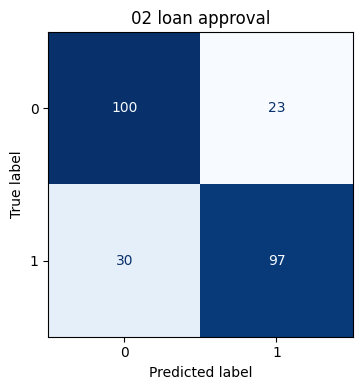

First five held-out predictions: [0 0 0 0 0]


In [ ]:
n = 1000
X = pd.DataFrame({'income': rng.uniform(3, 30, n),
    'credit_history': rng.binomial(1, 0.75, n),
    'loan_amount': rng.uniform(2, 60, n),
    'employment': rng.choice(['salaried', 'self_employed', 'unemployed'], n)})
job = X.employment.map({'salaried': 0.8, 'self_employed': 0.2, 'unemployed': -1})
score = 0.13*X.income + 2*X.credit_history - 0.07*X.loan_amount + job - 1.5
y = rng.binomial(1, 1/(1 + np.exp(-score)))
print('Labels: 0 = rejected; 1 = approved')
model = make_pipeline(tabular_preprocessor(X),
                      LogisticRegression(max_iter=2000, random_state=SEED))
metrics = evaluate(model, X, y, '02_loan_approval')

### Result and conclusion
Measured results: accuracy = 0.7880; macro_f1 = 0.7880; baseline_accuracy = 0.5080. The labels are simulated for teaching. Real lending requires representative data, policy checks and fairness evaluation.

## Practical 03: Iris Flower Classification

### Aim
Classify Setosa, Versicolor and Virginica from sepal and petal measurements.

### Model
K-Nearest Neighbors (KNN)

### Data
scikit-learn Iris benchmark: 150 flowers, four measurements in centimetres and three species.

### Theory
KNN predicts the majority class of the five closest training observations. Standardization prevents a feature with a larger numerical scale from dominating Euclidean distance.

### Method
Load or generate data, inspect features and labels, fit preprocessing on training data, train the required model, evaluate and visualize the output. See the implementation for the task-specific split.

### Limitation
The test split contains only 38 flowers. Results depend on the split and do not measure performance on every flower species.

In [ ]:
"""Shared imports and evaluation; also embedded in every standalone notebook."""
import re
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split
from sklearn.pipeline import make_pipeline
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.impute import SimpleImputer
from sklearn.linear_model import LinearRegression, LogisticRegression
from sklearn.neighbors import KNeighborsClassifier
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import (RandomForestClassifier, RandomForestRegressor,
    IsolationForest, GradientBoostingRegressor, AdaBoostRegressor)
from sklearn.svm import SVC, LinearSVC
from sklearn.naive_bayes import MultinomialNB
from sklearn.feature_extraction.text import (TfidfVectorizer,
    CountVectorizer, ENGLISH_STOP_WORDS)
from sklearn.cluster import KMeans
from sklearn.decomposition import PCA
from sklearn.datasets import load_iris, load_breast_cancer, load_digits
from sklearn.dummy import DummyClassifier, DummyRegressor
from sklearn.metrics import (accuracy_score, f1_score, classification_report,
    ConfusionMatrixDisplay, mean_absolute_error, mean_squared_error,
    r2_score, silhouette_score, average_precision_score)
SEED = 42
rng = np.random.default_rng(SEED)
OUT = Path('outputs')
OUT.mkdir(exist_ok=True)
plt.rcParams.update({'figure.figsize': (7, 4), 'font.size': 10})

def plot_save(name):
    plt.tight_layout()
    plt.savefig(OUT / f'{name}.png', dpi=150, bbox_inches='tight')
    plt.show()
    plt.close()

def tabular_preprocessor(frame):
    numeric = frame.select_dtypes(include='number').columns.tolist()
    category = frame.select_dtypes(exclude='number').columns.tolist()
    return ColumnTransformer([
        ('numeric', make_pipeline(SimpleImputer(strategy='median'),
                                  StandardScaler()), numeric),
        ('category', make_pipeline(SimpleImputer(strategy='most_frequent'),
          OneHotEncoder(handle_unknown='ignore', sparse_output=False)), category)])

def evaluate(model, X, y, name, classification=True, chronological=False):
    # All fitted preprocessing stays inside the model pipeline.
    Xtr, Xte, ytr, yte = train_test_split(X, y, test_size=0.25,
        random_state=None if chronological else SEED,
        shuffle=not chronological,
        stratify=y if classification and not chronological else None)
    model.fit(Xtr, ytr)
    pred = model.predict(Xte)
    print(f'Train: {len(ytr)} | Test: {len(yte)} | Features: '
          f'{X.shape[1] if hasattr(X, "shape") and len(X.shape)>1 else "text"}')
    if classification:
        baseline = DummyClassifier(strategy='most_frequent').fit(Xtr, ytr)
        metrics = {'accuracy': accuracy_score(yte, pred),
                   'macro_f1': f1_score(yte, pred, average='macro'),
                   'baseline_accuracy': accuracy_score(yte, baseline.predict(Xte))}
        print(classification_report(yte, pred, digits=3, zero_division=0))
        ConfusionMatrixDisplay.from_predictions(yte, pred, cmap='Blues',
                                                colorbar=False)
        plt.title(name.replace('_', ' '))
        if any(len(str(v)) > 8 for v in np.unique(yte)):
            plt.xticks(rotation=30, ha='right')
    else:
        baseline = DummyRegressor().fit(Xtr, ytr)
        metrics = {'MAE': mean_absolute_error(yte, pred),
                   'RMSE': np.sqrt(mean_squared_error(yte, pred)),
                   'R2': r2_score(yte, pred),
                   'baseline_MAE': mean_absolute_error(yte, baseline.predict(Xte))}
        plt.scatter(yte, pred, alpha=0.6, s=18)
        lo, hi = min(min(yte), min(pred)), max(max(yte), max(pred))
        plt.plot([lo, hi], [lo, hi], 'k--')
        plt.xlabel('Actual target'); plt.ylabel('Predicted target')
        plt.title(name.replace('_', ' '))
    for key, value in metrics.items():
        print(f'{key}: {value:.4f}')
    plot_save(name)
    print('First five held-out predictions:', pred[:5])
    return metrics

def clean_text(text):
    text = re.sub(r'https?://\S+', ' url ', str(text).lower())
    text = re.sub(r'\d+', ' number ', text)
    return ' '.join(re.findall(r'[a-z]+', text))


In [ ]:
DATA = Path('data')
DATA.mkdir(exist_ok=True)


Classes: {0: np.str_('setosa'), 1: np.str_('versicolor'), 2: np.str_('virginica')}
Train: 112 | Test: 38 | Features: 4
              precision    recall  f1-score   support

           0      1.000     1.000     1.000        12
           1      0.812     1.000     0.897        13
           2      1.000     0.769     0.870        13

    accuracy                          0.921        38
   macro avg      0.938     0.923     0.922        38
weighted avg      0.936     0.921     0.920        38

accuracy: 0.9211
macro_f1: 0.9220
baseline_accuracy: 0.3158


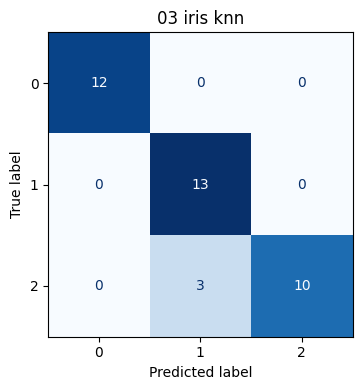

First five held-out predictions: [0 1 1 1 0]


In [ ]:
dataset = load_iris(as_frame=True)
X, y = dataset.data, dataset.target
print('Classes:', dict(enumerate(dataset.target_names)))
model = make_pipeline(StandardScaler(), KNeighborsClassifier(n_neighbors=5))
metrics = evaluate(model, X, y, '03_iris_knn')

### Result and conclusion
Measured results: accuracy = 0.9211; macro_f1 = 0.9220; baseline_accuracy = 0.3158. The test split contains only 38 flowers. Results depend on the split and do not measure performance on every flower species.

## Practical 04: Employee Promotion Prediction

### Aim
Predict promotion using experience, performance rating, training score and prior achievements.

### Model
Decision Tree

### Data
900 generated employee records with simulated promotion labels.

### Theory
A decision tree recursively partitions the feature space using impurity reduction. Limiting tree depth and minimum leaf size reduces overfitting.

### Method
Load or generate data, inspect features and labels, fit preprocessing on training data, train the required model, evaluate and visualize the output. See the implementation for the task-specific split.

### Limitation
Simulated labels encode a teaching rule; feature importance is not evidence that a factor causes promotion.

In [ ]:
"""Shared imports and evaluation; also embedded in every standalone notebook."""
import re
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split
from sklearn.pipeline import make_pipeline
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.impute import SimpleImputer
from sklearn.linear_model import LinearRegression, LogisticRegression
from sklearn.neighbors import KNeighborsClassifier
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import (RandomForestClassifier, RandomForestRegressor,
    IsolationForest, GradientBoostingRegressor, AdaBoostRegressor)
from sklearn.svm import SVC, LinearSVC
from sklearn.naive_bayes import MultinomialNB
from sklearn.feature_extraction.text import (TfidfVectorizer,
    CountVectorizer, ENGLISH_STOP_WORDS)
from sklearn.cluster import KMeans
from sklearn.decomposition import PCA
from sklearn.datasets import load_iris, load_breast_cancer, load_digits
from sklearn.dummy import DummyClassifier, DummyRegressor
from sklearn.metrics import (accuracy_score, f1_score, classification_report,
    ConfusionMatrixDisplay, mean_absolute_error, mean_squared_error,
    r2_score, silhouette_score, average_precision_score)
SEED = 42
rng = np.random.default_rng(SEED)
OUT = Path('outputs')
OUT.mkdir(exist_ok=True)
plt.rcParams.update({'figure.figsize': (7, 4), 'font.size': 10})

def plot_save(name):
    plt.tight_layout()
    plt.savefig(OUT / f'{name}.png', dpi=150, bbox_inches='tight')
    plt.show()
    plt.close()

def tabular_preprocessor(frame):
    numeric = frame.select_dtypes(include='number').columns.tolist()
    category = frame.select_dtypes(exclude='number').columns.tolist()
    return ColumnTransformer([
        ('numeric', make_pipeline(SimpleImputer(strategy='median'),
                                  StandardScaler()), numeric),
        ('category', make_pipeline(SimpleImputer(strategy='most_frequent'),
          OneHotEncoder(handle_unknown='ignore', sparse_output=False)), category)])

def evaluate(model, X, y, name, classification=True, chronological=False):
    # All fitted preprocessing stays inside the model pipeline.
    Xtr, Xte, ytr, yte = train_test_split(X, y, test_size=0.25,
        random_state=None if chronological else SEED,
        shuffle=not chronological,
        stratify=y if classification and not chronological else None)
    model.fit(Xtr, ytr)
    pred = model.predict(Xte)
    print(f'Train: {len(ytr)} | Test: {len(yte)} | Features: '
          f'{X.shape[1] if hasattr(X, "shape") and len(X.shape)>1 else "text"}')
    if classification:
        baseline = DummyClassifier(strategy='most_frequent').fit(Xtr, ytr)
        metrics = {'accuracy': accuracy_score(yte, pred),
                   'macro_f1': f1_score(yte, pred, average='macro'),
                   'baseline_accuracy': accuracy_score(yte, baseline.predict(Xte))}
        print(classification_report(yte, pred, digits=3, zero_division=0))
        ConfusionMatrixDisplay.from_predictions(yte, pred, cmap='Blues',
                                                colorbar=False)
        plt.title(name.replace('_', ' '))
        if any(len(str(v)) > 8 for v in np.unique(yte)):
            plt.xticks(rotation=30, ha='right')
    else:
        baseline = DummyRegressor().fit(Xtr, ytr)
        metrics = {'MAE': mean_absolute_error(yte, pred),
                   'RMSE': np.sqrt(mean_squared_error(yte, pred)),
                   'R2': r2_score(yte, pred),
                   'baseline_MAE': mean_absolute_error(yte, baseline.predict(Xte))}
        plt.scatter(yte, pred, alpha=0.6, s=18)
        lo, hi = min(min(yte), min(pred)), max(max(yte), max(pred))
        plt.plot([lo, hi], [lo, hi], 'k--')
        plt.xlabel('Actual target'); plt.ylabel('Predicted target')
        plt.title(name.replace('_', ' '))
    for key, value in metrics.items():
        print(f'{key}: {value:.4f}')
    plot_save(name)
    print('First five held-out predictions:', pred[:5])
    return metrics

def clean_text(text):
    text = re.sub(r'https?://\S+', ' url ', str(text).lower())
    text = re.sub(r'\d+', ' number ', text)
    return ' '.join(re.findall(r'[a-z]+', text))


In [ ]:
DATA = Path('data')
DATA.mkdir(exist_ok=True)


Labels: 0 = not promoted; 1 = promoted
Train: 675 | Test: 225 | Features: 4
              precision    recall  f1-score   support

           0      0.746     0.781     0.763       128
           1      0.692     0.649     0.670        97

    accuracy                          0.724       225
   macro avg      0.719     0.715     0.717       225
weighted avg      0.723     0.724     0.723       225

accuracy: 0.7244
macro_f1: 0.7168
baseline_accuracy: 0.5689


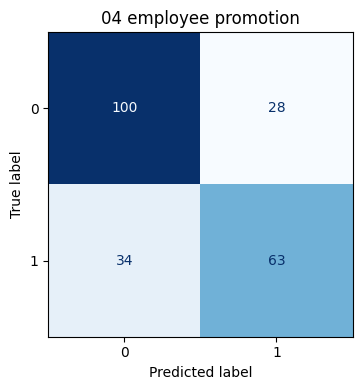

First five held-out predictions: [1 0 0 1 0]
Feature importances:
experience               0.104
performance_rating       0.269
training_score           0.518
previous_achievements    0.109
dtype: float64


In [ ]:
n = 900
X = pd.DataFrame({'experience': rng.integers(0, 26, n),
    'performance_rating': rng.integers(1, 6, n),
    'training_score': rng.uniform(30, 100, n),
    'previous_achievements': rng.integers(0, 5, n)})
score = (0.7*(X.performance_rating-3) + 0.06*(X.training_score-65)
         + 0.35*X.previous_achievements + 0.05*X.experience - 1.8)
y = rng.binomial(1, 1/(1 + np.exp(-score)))
print('Labels: 0 = not promoted; 1 = promoted')
model = DecisionTreeClassifier(max_depth=5, min_samples_leaf=15,
                               random_state=SEED)
metrics = evaluate(model, X, y, '04_employee_promotion')
print('Feature importances:')
print(pd.Series(model.feature_importances_, index=X.columns).round(3))

### Result and conclusion
Measured results: accuracy = 0.7244; macro_f1 = 0.7168; baseline_accuracy = 0.5689. Simulated labels encode a teaching rule; feature importance is not evidence that a factor causes promotion.

## Practical 05: Customer Churn Prediction

### Aim
Identify customers likely to leave a telecom service using usage, contracts, payment method and monthly charges.

### Model
Random Forest

### Data
1,200 generated telecom customers; usage in GB, tenure in months, and monthly charges in currency units.

### Theory
A random forest averages multiple trees trained on bootstrap samples with randomized feature selection. Class weighting accounts for unequal label frequencies.

### Method
Load or generate data, inspect features and labels, fit preprocessing on training data, train the required model, evaluate and visualize the output. See the implementation for the task-specific split.

### Limitation
The generated churn probabilities are noisy. Recall for the churn class matters more than accuracy alone for retention planning.

In [ ]:
"""Shared imports and evaluation; also embedded in every standalone notebook."""
import re
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split
from sklearn.pipeline import make_pipeline
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.impute import SimpleImputer
from sklearn.linear_model import LinearRegression, LogisticRegression
from sklearn.neighbors import KNeighborsClassifier
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import (RandomForestClassifier, RandomForestRegressor,
    IsolationForest, GradientBoostingRegressor, AdaBoostRegressor)
from sklearn.svm import SVC, LinearSVC
from sklearn.naive_bayes import MultinomialNB
from sklearn.feature_extraction.text import (TfidfVectorizer,
    CountVectorizer, ENGLISH_STOP_WORDS)
from sklearn.cluster import KMeans
from sklearn.decomposition import PCA
from sklearn.datasets import load_iris, load_breast_cancer, load_digits
from sklearn.dummy import DummyClassifier, DummyRegressor
from sklearn.metrics import (accuracy_score, f1_score, classification_report,
    ConfusionMatrixDisplay, mean_absolute_error, mean_squared_error,
    r2_score, silhouette_score, average_precision_score)
SEED = 42
rng = np.random.default_rng(SEED)
OUT = Path('outputs')
OUT.mkdir(exist_ok=True)
plt.rcParams.update({'figure.figsize': (7, 4), 'font.size': 10})

def plot_save(name):
    plt.tight_layout()
    plt.savefig(OUT / f'{name}.png', dpi=150, bbox_inches='tight')
    plt.show()
    plt.close()

def tabular_preprocessor(frame):
    numeric = frame.select_dtypes(include='number').columns.tolist()
    category = frame.select_dtypes(exclude='number').columns.tolist()
    return ColumnTransformer([
        ('numeric', make_pipeline(SimpleImputer(strategy='median'),
                                  StandardScaler()), numeric),
        ('category', make_pipeline(SimpleImputer(strategy='most_frequent'),
          OneHotEncoder(handle_unknown='ignore', sparse_output=False)), category)])

def evaluate(model, X, y, name, classification=True, chronological=False):
    # All fitted preprocessing stays inside the model pipeline.
    Xtr, Xte, ytr, yte = train_test_split(X, y, test_size=0.25,
        random_state=None if chronological else SEED,
        shuffle=not chronological,
        stratify=y if classification and not chronological else None)
    model.fit(Xtr, ytr)
    pred = model.predict(Xte)
    print(f'Train: {len(ytr)} | Test: {len(yte)} | Features: '
          f'{X.shape[1] if hasattr(X, "shape") and len(X.shape)>1 else "text"}')
    if classification:
        baseline = DummyClassifier(strategy='most_frequent').fit(Xtr, ytr)
        metrics = {'accuracy': accuracy_score(yte, pred),
                   'macro_f1': f1_score(yte, pred, average='macro'),
                   'baseline_accuracy': accuracy_score(yte, baseline.predict(Xte))}
        print(classification_report(yte, pred, digits=3, zero_division=0))
        ConfusionMatrixDisplay.from_predictions(yte, pred, cmap='Blues',
                                                colorbar=False)
        plt.title(name.replace('_', ' '))
        if any(len(str(v)) > 8 for v in np.unique(yte)):
            plt.xticks(rotation=30, ha='right')
    else:
        baseline = DummyRegressor().fit(Xtr, ytr)
        metrics = {'MAE': mean_absolute_error(yte, pred),
                   'RMSE': np.sqrt(mean_squared_error(yte, pred)),
                   'R2': r2_score(yte, pred),
                   'baseline_MAE': mean_absolute_error(yte, baseline.predict(Xte))}
        plt.scatter(yte, pred, alpha=0.6, s=18)
        lo, hi = min(min(yte), min(pred)), max(max(yte), max(pred))
        plt.plot([lo, hi], [lo, hi], 'k--')
        plt.xlabel('Actual target'); plt.ylabel('Predicted target')
        plt.title(name.replace('_', ' '))
    for key, value in metrics.items():
        print(f'{key}: {value:.4f}')
    plot_save(name)
    print('First five held-out predictions:', pred[:5])
    return metrics

def clean_text(text):
    text = re.sub(r'https?://\S+', ' url ', str(text).lower())
    text = re.sub(r'\d+', ' number ', text)
    return ' '.join(re.findall(r'[a-z]+', text))


In [ ]:
DATA = Path('data')
DATA.mkdir(exist_ok=True)


Labels: 0 = retained; 1 = churned
Train: 900 | Test: 300 | Features: 5
              precision    recall  f1-score   support

           0      0.833     0.800     0.816       200
           1      0.630     0.680     0.654       100

    accuracy                          0.760       300
   macro avg      0.731     0.740     0.735       300
weighted avg      0.765     0.760     0.762       300

accuracy: 0.7600
macro_f1: 0.7351
baseline_accuracy: 0.6667


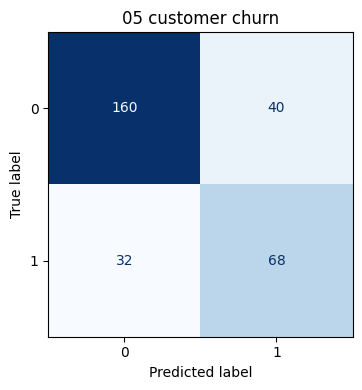

First five held-out predictions: [0 0 0 0 0]


In [ ]:
n = 1200
X = pd.DataFrame({'usage_gb': rng.uniform(1, 100, n),
    'tenure_months': rng.integers(1, 73, n),
    'contract': rng.choice(['monthly', 'annual', 'two_year'], n),
    'payment_method': rng.choice(['automatic', 'manual'], n),
    'monthly_charges': rng.uniform(20, 120, n)})
score = (1.4*(X.contract=='monthly') + 0.5*(X.payment_method=='manual')
         + 0.025*X.monthly_charges - 0.045*X.tenure_months
         + 0.005*X.usage_gb - 2)
y = rng.binomial(1, 1/(1 + np.exp(-score)))
print('Labels: 0 = retained; 1 = churned')
model = make_pipeline(tabular_preprocessor(X), RandomForestClassifier(
    n_estimators=150, max_depth=8, min_samples_leaf=5,
    class_weight='balanced', random_state=SEED, n_jobs=-1))
metrics = evaluate(model, X, y, '05_customer_churn')

### Result and conclusion
Measured results: accuracy = 0.7600; macro_f1 = 0.7416; baseline_accuracy = 0.6667. The generated churn probabilities are noisy. Recall for the churn class matters more than accuracy alone for retention planning.

## Practical 06: Breast Cancer Classification

### Aim
Classify diagnostic feature vectors as malignant or benign.

### Model
Support Vector Machine (SVM)

### Data
scikit-learn Wisconsin Diagnostic Breast Cancer benchmark: 569 samples and 30 numerical features.

### Theory
An RBF-kernel SVM learns a nonlinear decision boundary with a maximum-margin objective. Standardization is fitted on training data to avoid test-set leakage.

### Method
Load or generate data, inspect features and labels, fit preprocessing on training data, train the required model, evaluate and visualize the output. See the implementation for the task-specific split.

### Limitation
This is a benchmark exercise, not a validated clinical diagnostic system. Review malignant-class recall as well as accuracy.

In [ ]:
"""Shared imports and evaluation; also embedded in every standalone notebook."""
import re
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split
from sklearn.pipeline import make_pipeline
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.impute import SimpleImputer
from sklearn.linear_model import LinearRegression, LogisticRegression
from sklearn.neighbors import KNeighborsClassifier
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import (RandomForestClassifier, RandomForestRegressor,
    IsolationForest, GradientBoostingRegressor, AdaBoostRegressor)
from sklearn.svm import SVC, LinearSVC
from sklearn.naive_bayes import MultinomialNB
from sklearn.feature_extraction.text import (TfidfVectorizer,
    CountVectorizer, ENGLISH_STOP_WORDS)
from sklearn.cluster import KMeans
from sklearn.decomposition import PCA
from sklearn.datasets import load_iris, load_breast_cancer, load_digits
from sklearn.dummy import DummyClassifier, DummyRegressor
from sklearn.metrics import (accuracy_score, f1_score, classification_report,
    ConfusionMatrixDisplay, mean_absolute_error, mean_squared_error,
    r2_score, silhouette_score, average_precision_score)
SEED = 42
rng = np.random.default_rng(SEED)
OUT = Path('outputs')
OUT.mkdir(exist_ok=True)
plt.rcParams.update({'figure.figsize': (7, 4), 'font.size': 10})

def plot_save(name):
    plt.tight_layout()
    plt.savefig(OUT / f'{name}.png', dpi=150, bbox_inches='tight')
    plt.show()
    plt.close()

def tabular_preprocessor(frame):
    numeric = frame.select_dtypes(include='number').columns.tolist()
    category = frame.select_dtypes(exclude='number').columns.tolist()
    return ColumnTransformer([
        ('numeric', make_pipeline(SimpleImputer(strategy='median'),
                                  StandardScaler()), numeric),
        ('category', make_pipeline(SimpleImputer(strategy='most_frequent'),
          OneHotEncoder(handle_unknown='ignore', sparse_output=False)), category)])

def evaluate(model, X, y, name, classification=True, chronological=False):
    # All fitted preprocessing stays inside the model pipeline.
    Xtr, Xte, ytr, yte = train_test_split(X, y, test_size=0.25,
        random_state=None if chronological else SEED,
        shuffle=not chronological,
        stratify=y if classification and not chronological else None)
    model.fit(Xtr, ytr)
    pred = model.predict(Xte)
    print(f'Train: {len(ytr)} | Test: {len(yte)} | Features: '
          f'{X.shape[1] if hasattr(X, "shape") and len(X.shape)>1 else "text"}')
    if classification:
        baseline = DummyClassifier(strategy='most_frequent').fit(Xtr, ytr)
        metrics = {'accuracy': accuracy_score(yte, pred),
                   'macro_f1': f1_score(yte, pred, average='macro'),
                   'baseline_accuracy': accuracy_score(yte, baseline.predict(Xte))}
        print(classification_report(yte, pred, digits=3, zero_division=0))
        ConfusionMatrixDisplay.from_predictions(yte, pred, cmap='Blues',
                                                colorbar=False)
        plt.title(name.replace('_', ' '))
        if any(len(str(v)) > 8 for v in np.unique(yte)):
            plt.xticks(rotation=30, ha='right')
    else:
        baseline = DummyRegressor().fit(Xtr, ytr)
        metrics = {'MAE': mean_absolute_error(yte, pred),
                   'RMSE': np.sqrt(mean_squared_error(yte, pred)),
                   'R2': r2_score(yte, pred),
                   'baseline_MAE': mean_absolute_error(yte, baseline.predict(Xte))}
        plt.scatter(yte, pred, alpha=0.6, s=18)
        lo, hi = min(min(yte), min(pred)), max(max(yte), max(pred))
        plt.plot([lo, hi], [lo, hi], 'k--')
        plt.xlabel('Actual target'); plt.ylabel('Predicted target')
        plt.title(name.replace('_', ' '))
    for key, value in metrics.items():
        print(f'{key}: {value:.4f}')
    plot_save(name)
    print('First five held-out predictions:', pred[:5])
    return metrics

def clean_text(text):
    text = re.sub(r'https?://\S+', ' url ', str(text).lower())
    text = re.sub(r'\d+', ' number ', text)
    return ' '.join(re.findall(r'[a-z]+', text))


In [ ]:
DATA = Path('data')
DATA.mkdir(exist_ok=True)


Classes: {0: np.str_('malignant'), 1: np.str_('benign')}
Train: 426 | Test: 143 | Features: 30
              precision    recall  f1-score   support

           0      0.945     0.981     0.963        53
           1      0.989     0.967     0.978        90

    accuracy                          0.972       143
   macro avg      0.967     0.974     0.970       143
weighted avg      0.973     0.972     0.972       143

accuracy: 0.9720
macro_f1: 0.9702
baseline_accuracy: 0.6294


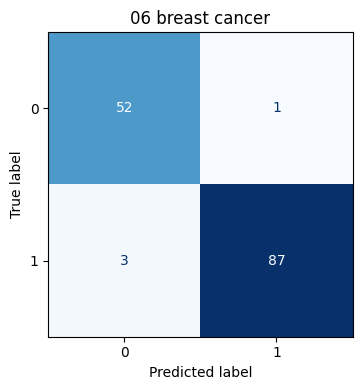

First five held-out predictions: [1 0 1 1 0]


In [ ]:
dataset = load_breast_cancer(as_frame=True)
X, y = dataset.data, dataset.target
print('Classes:', dict(enumerate(dataset.target_names)))
model = make_pipeline(StandardScaler(), SVC(C=1.0, kernel='rbf',
    gamma='scale', class_weight='balanced', random_state=SEED))
metrics = evaluate(model, X, y, '06_breast_cancer')

### Result and conclusion
Measured results: accuracy = 0.9720; macro_f1 = 0.9702; baseline_accuracy = 0.6294. This is a benchmark exercise, not a validated clinical diagnostic system. Review malignant-class recall as well as accuracy.

## Practical 07: Spam SMS Detection

### Aim
Clean SMS text, extract TF-IDF features and classify spam versus legitimate messages.

### Model
TF-IDF + Naive Bayes

### Data
80 original, manually authored teaching messages: 40 spam and 40 ham. No downloaded SMS corpus or personal messages are used.

### Theory
Text is lowercased, URLs and numbers are normalized, and punctuation is removed. TF-IDF downweights frequent terms; Multinomial Naive Bayes uses class-conditional token counts with additive smoothing.

### Method
Load or generate data, inspect features and labels, fit preprocessing on training data, train the required model, evaluate and visualize the output. See the implementation for the task-specific split.

### Limitation
The small authored corpus illustrates the pipeline only. Its test metrics are not a real-world spam benchmark.

In [ ]:
"""Shared imports and evaluation; also embedded in every standalone notebook."""
import re
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split
from sklearn.pipeline import make_pipeline
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.impute import SimpleImputer
from sklearn.linear_model import LinearRegression, LogisticRegression
from sklearn.neighbors import KNeighborsClassifier
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import (RandomForestClassifier, RandomForestRegressor,
    IsolationForest, GradientBoostingRegressor, AdaBoostRegressor)
from sklearn.svm import SVC, LinearSVC
from sklearn.naive_bayes import MultinomialNB
from sklearn.feature_extraction.text import (TfidfVectorizer,
    CountVectorizer, ENGLISH_STOP_WORDS)
from sklearn.cluster import KMeans
from sklearn.decomposition import PCA
from sklearn.datasets import load_iris, load_breast_cancer, load_digits
from sklearn.dummy import DummyClassifier, DummyRegressor
from sklearn.metrics import (accuracy_score, f1_score, classification_report,
    ConfusionMatrixDisplay, mean_absolute_error, mean_squared_error,
    r2_score, silhouette_score, average_precision_score)
SEED = 42
rng = np.random.default_rng(SEED)
OUT = Path('outputs')
OUT.mkdir(exist_ok=True)
plt.rcParams.update({'figure.figsize': (7, 4), 'font.size': 10})

def plot_save(name):
    plt.tight_layout()
    plt.savefig(OUT / f'{name}.png', dpi=150, bbox_inches='tight')
    plt.show()
    plt.close()

def tabular_preprocessor(frame):
    numeric = frame.select_dtypes(include='number').columns.tolist()
    category = frame.select_dtypes(exclude='number').columns.tolist()
    return ColumnTransformer([
        ('numeric', make_pipeline(SimpleImputer(strategy='median'),
                                  StandardScaler()), numeric),
        ('category', make_pipeline(SimpleImputer(strategy='most_frequent'),
          OneHotEncoder(handle_unknown='ignore', sparse_output=False)), category)])

def evaluate(model, X, y, name, classification=True, chronological=False):
    # All fitted preprocessing stays inside the model pipeline.
    Xtr, Xte, ytr, yte = train_test_split(X, y, test_size=0.25,
        random_state=None if chronological else SEED,
        shuffle=not chronological,
        stratify=y if classification and not chronological else None)
    model.fit(Xtr, ytr)
    pred = model.predict(Xte)
    print(f'Train: {len(ytr)} | Test: {len(yte)} | Features: '
          f'{X.shape[1] if hasattr(X, "shape") and len(X.shape)>1 else "text"}')
    if classification:
        baseline = DummyClassifier(strategy='most_frequent').fit(Xtr, ytr)
        metrics = {'accuracy': accuracy_score(yte, pred),
                   'macro_f1': f1_score(yte, pred, average='macro'),
                   'baseline_accuracy': accuracy_score(yte, baseline.predict(Xte))}
        print(classification_report(yte, pred, digits=3, zero_division=0))
        ConfusionMatrixDisplay.from_predictions(yte, pred, cmap='Blues',
                                                colorbar=False)
        plt.title(name.replace('_', ' '))
        if any(len(str(v)) > 8 for v in np.unique(yte)):
            plt.xticks(rotation=30, ha='right')
    else:
        baseline = DummyRegressor().fit(Xtr, ytr)
        metrics = {'MAE': mean_absolute_error(yte, pred),
                   'RMSE': np.sqrt(mean_squared_error(yte, pred)),
                   'R2': r2_score(yte, pred),
                   'baseline_MAE': mean_absolute_error(yte, baseline.predict(Xte))}
        plt.scatter(yte, pred, alpha=0.6, s=18)
        lo, hi = min(min(yte), min(pred)), max(max(yte), max(pred))
        plt.plot([lo, hi], [lo, hi], 'k--')
        plt.xlabel('Actual target'); plt.ylabel('Predicted target')
        plt.title(name.replace('_', ' '))
    for key, value in metrics.items():
        print(f'{key}: {value:.4f}')
    plot_save(name)
    print('First five held-out predictions:', pred[:5])
    return metrics

def clean_text(text):
    text = re.sub(r'https?://\S+', ' url ', str(text).lower())
    text = re.sub(r'\d+', ' number ', text)
    return ' '.join(re.findall(r'[a-z]+', text))


In [ ]:
DATA = Path('data')
DATA.mkdir(exist_ok=True)
(DATA / 'sms.csv').write_text('text,label\nMeet me at the library after class,ham\nPlease bring your notebook tomorrow,ham\nDinner is ready come home soon,ham\nCan you send the lecture notes,ham\nThe meeting has moved to Friday,ham\nYour dentist appointment is confirmed,ham\nI will call you after work,ham\nPlease pick up milk on your way,ham\nHappy birthday have a lovely day,ham\nOur train arrives this evening,ham\nThe project deadline is next week,ham\nAre you coming to football practice,ham\nI left your keys on the desk,ham\nThanks for helping with my homework,ham\nLet us have lunch together today,ham\nThe office will be closed tomorrow,ham\nYour package will arrive on Monday,ham\nRemember to take your umbrella,ham\nThe teacher uploaded the assignment,ham\nCan we reschedule our study session,ham\nMy phone battery is almost empty,ham\nPlease check the document I sent,ham\nWe are waiting near the station,ham\nThe family picnic starts at noon,ham\nI enjoyed our conversation yesterday,ham\nCall the plumber about the kitchen sink,ham\nYour prescription is ready for collection,ham\nSee you at the conference next month,ham\nPlease water the plants while I travel,ham\nThe bus is running late today,ham\nBring your sports shoes for practice,ham\nYour table reservation is confirmed,ham\nThe laptop charger is in my bag,ham\nPlease review the budget before our meeting,ham\nThe exam room has been changed,ham\nI booked tickets for our weekend trip,ham\nWe should discuss the report after lunch,ham\nThe grocery list is on the fridge,ham\nSend me the address for your house,ham\nYour friend is waiting at reception,ham\nCongratulations claim your free cash prize now,spam\nYou won a lottery click here to collect,spam\nUrgent cash reward waiting call immediately,spam\nExclusive offer win a luxury holiday today,spam\nGet a free phone by entering this contest,spam\nClaim your guaranteed jackpot before midnight,spam\nEarn money fast with our secret system,spam\nYour number was selected for a cash bonus,spam\nLimited offer buy now and get free gifts,spam\nClick to unlock an exclusive reward voucher,spam\nWinner claim your prize by paying a small fee,spam\nFree vacation awaits respond with your details,spam\nDouble your money with this amazing investment,spam\nCongratulations you are our lucky winner today,spam\nInstant loan approved claim cash without documents,spam\nBuy discount pills from our online store,spam\nYou have won a brand new sports car,spam\nCollect your reward by calling this premium line,spam\nGet rich quickly with no work required,spam\nSpecial bonus for you claim before it expires,spam\nWin free shopping vouchers sign up now,spam\nUrgent prize notification send your bank details,spam\nExclusive casino bonus claim your free spins,spam\nCash giveaway selected winners respond immediately,spam\nAmazing discount deal only for lucky customers,spam\nClaim a free gift card at this link,spam\nGuaranteed investment returns double your savings,spam\nYour account qualifies for a surprise cash reward,spam\nFree holiday tickets claim with a processing fee,spam\nCongratulations collect your unlimited shopping credit,spam\nCheap luxury watches available buy today,spam\nWin a fortune with our lottery promotion,spam\nRedeem your exclusive prize voucher immediately,spam\nGet instant cash by joining our reward scheme,spam\nLucky draw winner send details to claim,spam\nYour free subscription prize is ready now,spam\nMake money from home guaranteed daily profits,spam\nFinal chance to claim your luxury gift,spam\nUnlock a secret jackpot by clicking our link,spam\nCash prize expires tonight reply winner now,spam\n', encoding='utf-8')


3538

Messages: 80 | Classes: {'ham': 40, 'spam': 40}
Train: 60 | Test: 20 | Features: text
              precision    recall  f1-score   support

         ham      1.000     1.000     1.000        10
        spam      1.000     1.000     1.000        10

    accuracy                          1.000        20
   macro avg      1.000     1.000     1.000        20
weighted avg      1.000     1.000     1.000        20

accuracy: 1.0000
macro_f1: 1.0000
baseline_accuracy: 0.5000


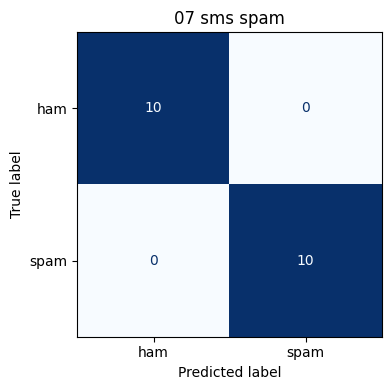

First five held-out predictions: ['ham' 'spam' 'ham' 'spam' 'spam']
New SMS predictions: ['spam' 'ham']


In [ ]:
df = pd.read_csv(DATA / 'sms.csv')
X, y = df.text.map(clean_text), df.label
assert not X.duplicated().any()
print('Messages:', len(df), '| Classes:', y.value_counts().to_dict())
model = make_pipeline(TfidfVectorizer(ngram_range=(1, 2)), MultinomialNB())
metrics = evaluate(model, X, y, '07_sms_spam')
examples = ['Claim your free cash prize now', 'Meet me at the library tomorrow']
print('New SMS predictions:', model.predict([clean_text(s) for s in examples]))

### Result and conclusion
Measured results: accuracy = 1.0000; macro_f1 = 1.0000; baseline_accuracy = 0.5000. The small authored corpus illustrates the pipeline only. Its test metrics are not a real-world spam benchmark.

## Practical 08: Customer Segmentation

### Aim
Group customers by age, annual income and spending score without predefined labels.

### Model
K-Means Clustering

### Data
450 generated customers from three overlapping profiles. Income is in thousands of currency units; spending score ranges from 1 to 100.

### Theory
K-Means minimizes within-cluster squared distance. Features are standardized, candidate values of k are compared by silhouette score, and centres are converted back to original units for interpretation.

### Method
Load or generate data, inspect features and labels, fit preprocessing on training data, train the required model, evaluate and visualize the output. See the implementation for the task-specific split.

### Limitation
Silhouette is an internal measure computed on the same data used for clustering. Cluster numbers are arbitrary, not externally verified customer categories.

In [ ]:
"""Shared imports and evaluation; also embedded in every standalone notebook."""
import re
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split
from sklearn.pipeline import make_pipeline
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.impute import SimpleImputer
from sklearn.linear_model import LinearRegression, LogisticRegression
from sklearn.neighbors import KNeighborsClassifier
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import (RandomForestClassifier, RandomForestRegressor,
    IsolationForest, GradientBoostingRegressor, AdaBoostRegressor)
from sklearn.svm import SVC, LinearSVC
from sklearn.naive_bayes import MultinomialNB
from sklearn.feature_extraction.text import (TfidfVectorizer,
    CountVectorizer, ENGLISH_STOP_WORDS)
from sklearn.cluster import KMeans
from sklearn.decomposition import PCA
from sklearn.datasets import load_iris, load_breast_cancer, load_digits
from sklearn.dummy import DummyClassifier, DummyRegressor
from sklearn.metrics import (accuracy_score, f1_score, classification_report,
    ConfusionMatrixDisplay, mean_absolute_error, mean_squared_error,
    r2_score, silhouette_score, average_precision_score)
SEED = 42
rng = np.random.default_rng(SEED)
OUT = Path('outputs')
OUT.mkdir(exist_ok=True)
plt.rcParams.update({'figure.figsize': (7, 4), 'font.size': 10})

def plot_save(name):
    plt.tight_layout()
    plt.savefig(OUT / f'{name}.png', dpi=150, bbox_inches='tight')
    plt.show()
    plt.close()

def tabular_preprocessor(frame):
    numeric = frame.select_dtypes(include='number').columns.tolist()
    category = frame.select_dtypes(exclude='number').columns.tolist()
    return ColumnTransformer([
        ('numeric', make_pipeline(SimpleImputer(strategy='median'),
                                  StandardScaler()), numeric),
        ('category', make_pipeline(SimpleImputer(strategy='most_frequent'),
          OneHotEncoder(handle_unknown='ignore', sparse_output=False)), category)])

def evaluate(model, X, y, name, classification=True, chronological=False):
    # All fitted preprocessing stays inside the model pipeline.
    Xtr, Xte, ytr, yte = train_test_split(X, y, test_size=0.25,
        random_state=None if chronological else SEED,
        shuffle=not chronological,
        stratify=y if classification and not chronological else None)
    model.fit(Xtr, ytr)
    pred = model.predict(Xte)
    print(f'Train: {len(ytr)} | Test: {len(yte)} | Features: '
          f'{X.shape[1] if hasattr(X, "shape") and len(X.shape)>1 else "text"}')
    if classification:
        baseline = DummyClassifier(strategy='most_frequent').fit(Xtr, ytr)
        metrics = {'accuracy': accuracy_score(yte, pred),
                   'macro_f1': f1_score(yte, pred, average='macro'),
                   'baseline_accuracy': accuracy_score(yte, baseline.predict(Xte))}
        print(classification_report(yte, pred, digits=3, zero_division=0))
        ConfusionMatrixDisplay.from_predictions(yte, pred, cmap='Blues',
                                                colorbar=False)
        plt.title(name.replace('_', ' '))
        if any(len(str(v)) > 8 for v in np.unique(yte)):
            plt.xticks(rotation=30, ha='right')
    else:
        baseline = DummyRegressor().fit(Xtr, ytr)
        metrics = {'MAE': mean_absolute_error(yte, pred),
                   'RMSE': np.sqrt(mean_squared_error(yte, pred)),
                   'R2': r2_score(yte, pred),
                   'baseline_MAE': mean_absolute_error(yte, baseline.predict(Xte))}
        plt.scatter(yte, pred, alpha=0.6, s=18)
        lo, hi = min(min(yte), min(pred)), max(max(yte), max(pred))
        plt.plot([lo, hi], [lo, hi], 'k--')
        plt.xlabel('Actual target'); plt.ylabel('Predicted target')
        plt.title(name.replace('_', ' '))
    for key, value in metrics.items():
        print(f'{key}: {value:.4f}')
    plot_save(name)
    print('First five held-out predictions:', pred[:5])
    return metrics

def clean_text(text):
    text = re.sub(r'https?://\S+', ' url ', str(text).lower())
    text = re.sub(r'\d+', ' number ', text)
    return ' '.join(re.findall(r'[a-z]+', text))


In [ ]:
DATA = Path('data')
DATA.mkdir(exist_ok=True)


Silhouette by k: {2: np.float64(0.424), 3: np.float64(0.506), 4: np.float64(0.4), 5: np.float64(0.322), 6: np.float64(0.233)}
Selected k: 3
Cluster sizes: [142 156 152]
Centres in original units:
  age  annual_income  spending_score
44.74          90.89           64.52
55.11          50.24           26.17
25.45          34.74           74.72


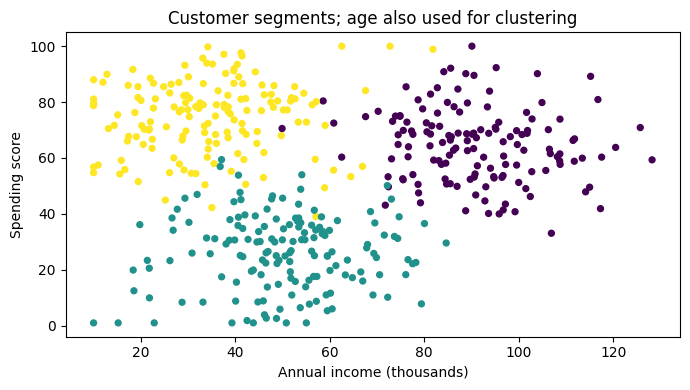

In [ ]:
centres = [[25, 35, 75], [45, 90, 65], [55, 50, 25]]
parts = [rng.normal(c, [8, 15, 14], size=(150, 3)) for c in centres]
X = pd.DataFrame(np.vstack(parts), columns=['age', 'annual_income', 'spending_score'])
X['age'] = X.age.clip(18, 80)
X['annual_income'] = X.annual_income.clip(10, 160)
X['spending_score'] = X.spending_score.clip(1, 100)
scaler = StandardScaler()
Z = scaler.fit_transform(X)
candidates = {}
for k in range(2, 7):
    km = KMeans(n_clusters=k, n_init=10, random_state=SEED).fit(Z)
    candidates[k] = (silhouette_score(Z, km.labels_), km)
best_k = max(candidates, key=lambda k: candidates[k][0])
score, model = candidates[best_k]
print('Silhouette by k:', {k: round(v[0], 3) for k, v in candidates.items()})
print('Selected k:', best_k)
print('Cluster sizes:', np.bincount(model.labels_))
print('Centres in original units:')
print(pd.DataFrame(scaler.inverse_transform(model.cluster_centers_),
                   columns=X.columns).round(2).to_string(index=False))
plt.scatter(X.annual_income, X.spending_score, c=model.labels_, cmap='viridis', s=18)
plt.xlabel('Annual income (thousands)'); plt.ylabel('Spending score')
plt.title('Customer segments; age also used for clustering')
plot_save('08_customer_segments')
metrics = {'selected_k': best_k, 'silhouette': score}

### Result and conclusion
Measured results: selected_k = 3.0000; silhouette = 0.5063. Silhouette is an internal measure computed on the same data used for clustering. Cluster numbers are arbitrary, not externally verified customer categories.

## Practical 09: Used Car Price Prediction

### Aim
Predict used-car prices from age, kilometres driven, engine capacity, fuel type and transmission.

### Model
Random Forest Regressor

### Data
1,000 generated cars. Price: INR lakh; distance: kilometres; engine: cubic centimetres.

### Theory
Random forest regression averages decision-tree predictions and can represent nonlinear relationships. Fuel and transmission are encoded inside the training pipeline.

### Method
Load or generate data, inspect features and labels, fit preprocessing on training data, train the required model, evaluate and visualize the output. See the implementation for the task-specific split.

### Limitation
The generated price rule omits brand, condition, accident history and market changes; benchmark accuracy cannot establish resale valuation accuracy.

In [ ]:
"""Shared imports and evaluation; also embedded in every standalone notebook."""
import re
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split
from sklearn.pipeline import make_pipeline
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.impute import SimpleImputer
from sklearn.linear_model import LinearRegression, LogisticRegression
from sklearn.neighbors import KNeighborsClassifier
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import (RandomForestClassifier, RandomForestRegressor,
    IsolationForest, GradientBoostingRegressor, AdaBoostRegressor)
from sklearn.svm import SVC, LinearSVC
from sklearn.naive_bayes import MultinomialNB
from sklearn.feature_extraction.text import (TfidfVectorizer,
    CountVectorizer, ENGLISH_STOP_WORDS)
from sklearn.cluster import KMeans
from sklearn.decomposition import PCA
from sklearn.datasets import load_iris, load_breast_cancer, load_digits
from sklearn.dummy import DummyClassifier, DummyRegressor
from sklearn.metrics import (accuracy_score, f1_score, classification_report,
    ConfusionMatrixDisplay, mean_absolute_error, mean_squared_error,
    r2_score, silhouette_score, average_precision_score)
SEED = 42
rng = np.random.default_rng(SEED)
OUT = Path('outputs')
OUT.mkdir(exist_ok=True)
plt.rcParams.update({'figure.figsize': (7, 4), 'font.size': 10})

def plot_save(name):
    plt.tight_layout()
    plt.savefig(OUT / f'{name}.png', dpi=150, bbox_inches='tight')
    plt.show()
    plt.close()

def tabular_preprocessor(frame):
    numeric = frame.select_dtypes(include='number').columns.tolist()
    category = frame.select_dtypes(exclude='number').columns.tolist()
    return ColumnTransformer([
        ('numeric', make_pipeline(SimpleImputer(strategy='median'),
                                  StandardScaler()), numeric),
        ('category', make_pipeline(SimpleImputer(strategy='most_frequent'),
          OneHotEncoder(handle_unknown='ignore', sparse_output=False)), category)])

def evaluate(model, X, y, name, classification=True, chronological=False):
    # All fitted preprocessing stays inside the model pipeline.
    Xtr, Xte, ytr, yte = train_test_split(X, y, test_size=0.25,
        random_state=None if chronological else SEED,
        shuffle=not chronological,
        stratify=y if classification and not chronological else None)
    model.fit(Xtr, ytr)
    pred = model.predict(Xte)
    print(f'Train: {len(ytr)} | Test: {len(yte)} | Features: '
          f'{X.shape[1] if hasattr(X, "shape") and len(X.shape)>1 else "text"}')
    if classification:
        baseline = DummyClassifier(strategy='most_frequent').fit(Xtr, ytr)
        metrics = {'accuracy': accuracy_score(yte, pred),
                   'macro_f1': f1_score(yte, pred, average='macro'),
                   'baseline_accuracy': accuracy_score(yte, baseline.predict(Xte))}
        print(classification_report(yte, pred, digits=3, zero_division=0))
        ConfusionMatrixDisplay.from_predictions(yte, pred, cmap='Blues',
                                                colorbar=False)
        plt.title(name.replace('_', ' '))
        if any(len(str(v)) > 8 for v in np.unique(yte)):
            plt.xticks(rotation=30, ha='right')
    else:
        baseline = DummyRegressor().fit(Xtr, ytr)
        metrics = {'MAE': mean_absolute_error(yte, pred),
                   'RMSE': np.sqrt(mean_squared_error(yte, pred)),
                   'R2': r2_score(yte, pred),
                   'baseline_MAE': mean_absolute_error(yte, baseline.predict(Xte))}
        plt.scatter(yte, pred, alpha=0.6, s=18)
        lo, hi = min(min(yte), min(pred)), max(max(yte), max(pred))
        plt.plot([lo, hi], [lo, hi], 'k--')
        plt.xlabel('Actual target'); plt.ylabel('Predicted target')
        plt.title(name.replace('_', ' '))
    for key, value in metrics.items():
        print(f'{key}: {value:.4f}')
    plot_save(name)
    print('First five held-out predictions:', pred[:5])
    return metrics

def clean_text(text):
    text = re.sub(r'https?://\S+', ' url ', str(text).lower())
    text = re.sub(r'\d+', ' number ', text)
    return ' '.join(re.findall(r'[a-z]+', text))


In [ ]:
DATA = Path('data')
DATA.mkdir(exist_ok=True)


Train: 750 | Test: 250 | Features: 5
MAE: 0.6154
RMSE: 0.7670
R2: 0.9388
baseline_MAE: 2.5203


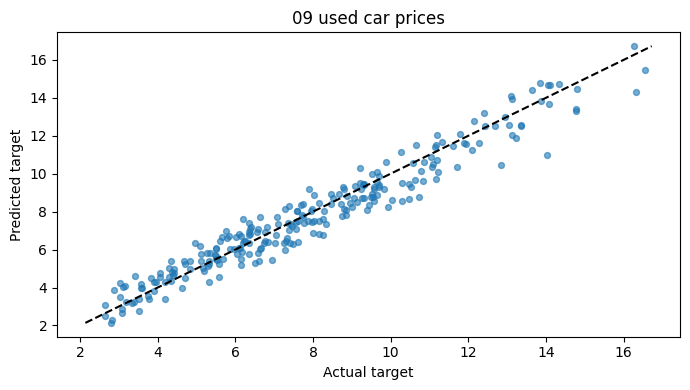

First five held-out predictions: [ 9.44815936  8.46638868 10.09181755 12.75828641  4.01130169]


In [ ]:
n = 1000
X = pd.DataFrame({'age': rng.uniform(0, 15, n),
    'kilometers_driven': rng.uniform(1000, 200000, n),
    'engine_capacity': rng.choice([1000, 1200, 1500, 2000, 2500], n),
    'fuel_type': rng.choice(['petrol', 'diesel', 'electric'], n),
    'transmission': rng.choice(['manual', 'automatic'], n)})
y = (2 + 0.006*X.engine_capacity*np.exp(-0.08*X.age)
     - 0.000012*X.kilometers_driven + 1.5*(X.transmission=='automatic')
     + 2*(X.fuel_type=='electric') + rng.normal(0, 0.6, n)).clip(0.5)
model = make_pipeline(tabular_preprocessor(X), RandomForestRegressor(
    n_estimators=150, min_samples_leaf=2, random_state=SEED, n_jobs=-1))
metrics = evaluate(model, X, y, '09_used_car_prices', classification=False)

### Result and conclusion
Measured results: MAE = 0.6152; RMSE = 0.7668; R2 = 0.9389; baseline_MAE = 2.5203. The generated price rule omits brand, condition, accident history and market changes; benchmark accuracy cannot establish resale valuation accuracy.

## Practical 10: Credit Card Fraud Detection

### Aim
Detect unusual transactions from numerical features using an unsupervised anomaly detector.

### Model
Isolation Forest

### Data
2,000 generated transactions: 1,940 normal and 60 anomalies. Labels are used only for stratification and final evaluation, not model fitting.

### Theory
Isolation Forest isolates observations using random partitions; anomalies tend to require shorter paths. The contamination rate is fixed in advance at 3 percent, not tuned on held-out labels.

### Method
Load or generate data, inspect features and labels, fit preprocessing on training data, train the required model, evaluate and visualize the output. See the implementation for the task-specific split.

### Limitation
An anomaly is not proof of fraud. The generated anomalies are deliberately separated, making this easier than most real transaction datasets.

In [ ]:
"""Shared imports and evaluation; also embedded in every standalone notebook."""
import re
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split
from sklearn.pipeline import make_pipeline
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.impute import SimpleImputer
from sklearn.linear_model import LinearRegression, LogisticRegression
from sklearn.neighbors import KNeighborsClassifier
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import (RandomForestClassifier, RandomForestRegressor,
    IsolationForest, GradientBoostingRegressor, AdaBoostRegressor)
from sklearn.svm import SVC, LinearSVC
from sklearn.naive_bayes import MultinomialNB
from sklearn.feature_extraction.text import (TfidfVectorizer,
    CountVectorizer, ENGLISH_STOP_WORDS)
from sklearn.cluster import KMeans
from sklearn.decomposition import PCA
from sklearn.datasets import load_iris, load_breast_cancer, load_digits
from sklearn.dummy import DummyClassifier, DummyRegressor
from sklearn.metrics import (accuracy_score, f1_score, classification_report,
    ConfusionMatrixDisplay, mean_absolute_error, mean_squared_error,
    r2_score, silhouette_score, average_precision_score)
SEED = 42
rng = np.random.default_rng(SEED)
OUT = Path('outputs')
OUT.mkdir(exist_ok=True)
plt.rcParams.update({'figure.figsize': (7, 4), 'font.size': 10})

def plot_save(name):
    plt.tight_layout()
    plt.savefig(OUT / f'{name}.png', dpi=150, bbox_inches='tight')
    plt.show()
    plt.close()

def tabular_preprocessor(frame):
    numeric = frame.select_dtypes(include='number').columns.tolist()
    category = frame.select_dtypes(exclude='number').columns.tolist()
    return ColumnTransformer([
        ('numeric', make_pipeline(SimpleImputer(strategy='median'),
                                  StandardScaler()), numeric),
        ('category', make_pipeline(SimpleImputer(strategy='most_frequent'),
          OneHotEncoder(handle_unknown='ignore', sparse_output=False)), category)])

def evaluate(model, X, y, name, classification=True, chronological=False):
    # All fitted preprocessing stays inside the model pipeline.
    Xtr, Xte, ytr, yte = train_test_split(X, y, test_size=0.25,
        random_state=None if chronological else SEED,
        shuffle=not chronological,
        stratify=y if classification and not chronological else None)
    model.fit(Xtr, ytr)
    pred = model.predict(Xte)
    print(f'Train: {len(ytr)} | Test: {len(yte)} | Features: '
          f'{X.shape[1] if hasattr(X, "shape") and len(X.shape)>1 else "text"}')
    if classification:
        baseline = DummyClassifier(strategy='most_frequent').fit(Xtr, ytr)
        metrics = {'accuracy': accuracy_score(yte, pred),
                   'macro_f1': f1_score(yte, pred, average='macro'),
                   'baseline_accuracy': accuracy_score(yte, baseline.predict(Xte))}
        print(classification_report(yte, pred, digits=3, zero_division=0))
        ConfusionMatrixDisplay.from_predictions(yte, pred, cmap='Blues',
                                                colorbar=False)
        plt.title(name.replace('_', ' '))
        if any(len(str(v)) > 8 for v in np.unique(yte)):
            plt.xticks(rotation=30, ha='right')
    else:
        baseline = DummyRegressor().fit(Xtr, ytr)
        metrics = {'MAE': mean_absolute_error(yte, pred),
                   'RMSE': np.sqrt(mean_squared_error(yte, pred)),
                   'R2': r2_score(yte, pred),
                   'baseline_MAE': mean_absolute_error(yte, baseline.predict(Xte))}
        plt.scatter(yte, pred, alpha=0.6, s=18)
        lo, hi = min(min(yte), min(pred)), max(max(yte), max(pred))
        plt.plot([lo, hi], [lo, hi], 'k--')
        plt.xlabel('Actual target'); plt.ylabel('Predicted target')
        plt.title(name.replace('_', ' '))
    for key, value in metrics.items():
        print(f'{key}: {value:.4f}')
    plot_save(name)
    print('First five held-out predictions:', pred[:5])
    return metrics

def clean_text(text):
    text = re.sub(r'https?://\S+', ' url ', str(text).lower())
    text = re.sub(r'\d+', ' number ', text)
    return ' '.join(re.findall(r'[a-z]+', text))


In [ ]:
DATA = Path('data')
DATA.mkdir(exist_ok=True)


Train: 1500 | Test: 500 | Test anomalies: 15
Labels: 0 = normal; 1 = anomaly
              precision    recall  f1-score   support

           0      0.998     0.994     0.996       485
           1      0.824     0.933     0.875        15

    accuracy                          0.992       500
   macro avg      0.911     0.964     0.935       500
weighted avg      0.993     0.992     0.992       500

average_precision: 0.9585
anomaly_f1: 0.8750
prevalence_baseline_AP: 0.0300


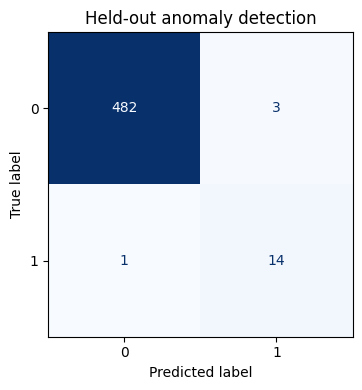

In [ ]:
normal = rng.normal(0, 1, size=(1940, 5))
anomalies = rng.normal(2.8, 1.5, size=(60, 5))
X = pd.DataFrame(np.vstack([normal, anomalies]), columns=[
    'log_amount_z', 'distance_z', 'velocity_z', 'hour_risk_z', 'device_risk_z'])
y = np.r_[np.zeros(len(normal), dtype=int), np.ones(len(anomalies), dtype=int)]
Xtr, Xte, ytr, yte = train_test_split(X, y, test_size=0.25,
                                    stratify=y, random_state=SEED)
model = IsolationForest(n_estimators=200, contamination=0.03,
                        random_state=SEED, n_jobs=-1)
model.fit(Xtr)  # No labels supplied to the unsupervised estimator.
pred = (model.predict(Xte) == -1).astype(int)
risk = -model.decision_function(Xte)
print(f'Train: {len(Xtr)} | Test: {len(Xte)} | Test anomalies: {sum(yte)}')
print('Labels: 0 = normal; 1 = anomaly')
print(classification_report(yte, pred, digits=3, zero_division=0))
metrics = {'average_precision': average_precision_score(yte, risk),
           'anomaly_f1': f1_score(yte, pred),
           'prevalence_baseline_AP': float(yte.mean())}
for key, value in metrics.items(): print(f'{key}: {value:.4f}')
ConfusionMatrixDisplay.from_predictions(yte, pred, cmap='Blues', colorbar=False)
plt.title('Held-out anomaly detection')
plot_save('10_fraud_detection')

### Result and conclusion
Measured results: average_precision = 0.9585; anomaly_f1 = 0.8750; prevalence_baseline_AP = 0.0300. An anomaly is not proof of fraud. The generated anomalies are deliberately separated, making this easier than most real transaction datasets.

## Practical 11: Student Performance Prediction

### Aim
Predict a final academic score from attendance, study hours, assignments, previous scores and participation.

### Model
Gradient Boosting Regressor

### Data
900 generated students. Marks and attendance are percentages; study hours are weekly. The regression option allowed by the assignment is used.

### Theory
Gradient boosting fits successive shallow trees to reduce the residual error of an additive model. Learning rate and tree complexity control model capacity.

### Method
Load or generate data, inspect features and labels, fit preprocessing on training data, train the required model, evaluate and visualize the output. See the implementation for the task-specific split.

### Limitation
Predictive associations in synthetic records are not causal explanations of student achievement.

In [ ]:
"""Shared imports and evaluation; also embedded in every standalone notebook."""
import re
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split
from sklearn.pipeline import make_pipeline
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.impute import SimpleImputer
from sklearn.linear_model import LinearRegression, LogisticRegression
from sklearn.neighbors import KNeighborsClassifier
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import (RandomForestClassifier, RandomForestRegressor,
    IsolationForest, GradientBoostingRegressor, AdaBoostRegressor)
from sklearn.svm import SVC, LinearSVC
from sklearn.naive_bayes import MultinomialNB
from sklearn.feature_extraction.text import (TfidfVectorizer,
    CountVectorizer, ENGLISH_STOP_WORDS)
from sklearn.cluster import KMeans
from sklearn.decomposition import PCA
from sklearn.datasets import load_iris, load_breast_cancer, load_digits
from sklearn.dummy import DummyClassifier, DummyRegressor
from sklearn.metrics import (accuracy_score, f1_score, classification_report,
    ConfusionMatrixDisplay, mean_absolute_error, mean_squared_error,
    r2_score, silhouette_score, average_precision_score)
SEED = 42
rng = np.random.default_rng(SEED)
OUT = Path('outputs')
OUT.mkdir(exist_ok=True)
plt.rcParams.update({'figure.figsize': (7, 4), 'font.size': 10})

def plot_save(name):
    plt.tight_layout()
    plt.savefig(OUT / f'{name}.png', dpi=150, bbox_inches='tight')
    plt.show()
    plt.close()

def tabular_preprocessor(frame):
    numeric = frame.select_dtypes(include='number').columns.tolist()
    category = frame.select_dtypes(exclude='number').columns.tolist()
    return ColumnTransformer([
        ('numeric', make_pipeline(SimpleImputer(strategy='median'),
                                  StandardScaler()), numeric),
        ('category', make_pipeline(SimpleImputer(strategy='most_frequent'),
          OneHotEncoder(handle_unknown='ignore', sparse_output=False)), category)])

def evaluate(model, X, y, name, classification=True, chronological=False):
    # All fitted preprocessing stays inside the model pipeline.
    Xtr, Xte, ytr, yte = train_test_split(X, y, test_size=0.25,
        random_state=None if chronological else SEED,
        shuffle=not chronological,
        stratify=y if classification and not chronological else None)
    model.fit(Xtr, ytr)
    pred = model.predict(Xte)
    print(f'Train: {len(ytr)} | Test: {len(yte)} | Features: '
          f'{X.shape[1] if hasattr(X, "shape") and len(X.shape)>1 else "text"}')
    if classification:
        baseline = DummyClassifier(strategy='most_frequent').fit(Xtr, ytr)
        metrics = {'accuracy': accuracy_score(yte, pred),
                   'macro_f1': f1_score(yte, pred, average='macro'),
                   'baseline_accuracy': accuracy_score(yte, baseline.predict(Xte))}
        print(classification_report(yte, pred, digits=3, zero_division=0))
        ConfusionMatrixDisplay.from_predictions(yte, pred, cmap='Blues',
                                                colorbar=False)
        plt.title(name.replace('_', ' '))
        if any(len(str(v)) > 8 for v in np.unique(yte)):
            plt.xticks(rotation=30, ha='right')
    else:
        baseline = DummyRegressor().fit(Xtr, ytr)
        metrics = {'MAE': mean_absolute_error(yte, pred),
                   'RMSE': np.sqrt(mean_squared_error(yte, pred)),
                   'R2': r2_score(yte, pred),
                   'baseline_MAE': mean_absolute_error(yte, baseline.predict(Xte))}
        plt.scatter(yte, pred, alpha=0.6, s=18)
        lo, hi = min(min(yte), min(pred)), max(max(yte), max(pred))
        plt.plot([lo, hi], [lo, hi], 'k--')
        plt.xlabel('Actual target'); plt.ylabel('Predicted target')
        plt.title(name.replace('_', ' '))
    for key, value in metrics.items():
        print(f'{key}: {value:.4f}')
    plot_save(name)
    print('First five held-out predictions:', pred[:5])
    return metrics

def clean_text(text):
    text = re.sub(r'https?://\S+', ' url ', str(text).lower())
    text = re.sub(r'\d+', ' number ', text)
    return ' '.join(re.findall(r'[a-z]+', text))


In [ ]:
DATA = Path('data')
DATA.mkdir(exist_ok=True)


Train: 675 | Test: 225 | Features: 5
MAE: 4.5706
RMSE: 5.7228
R2: 0.8144
baseline_MAE: 10.8046


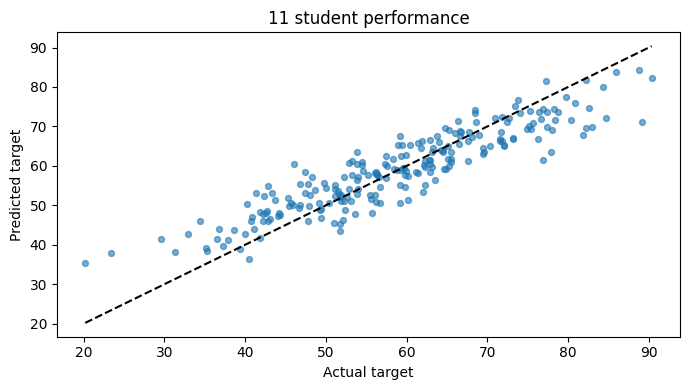

First five held-out predictions: [38.38403433 46.88331791 54.08655882 59.10153923 66.42058059]


In [ ]:
n = 900
X = pd.DataFrame({'attendance': rng.uniform(40, 100, n),
    'study_hours': rng.uniform(0, 30, n),
    'assignment_marks': rng.uniform(20, 100, n),
    'previous_scores': rng.uniform(20, 100, n),
    'participation': rng.integers(0, 11, n)})
y = (0.2*X.attendance + 0.6*X.study_hours + 0.25*X.assignment_marks
     + 0.3*X.previous_scores + 0.8*X.participation
     + rng.normal(0, 5, n)).clip(0, 100)
model = GradientBoostingRegressor(n_estimators=150, learning_rate=0.05,
                                  max_depth=2, random_state=SEED)
metrics = evaluate(model, X, y, '11_student_performance', classification=False)

### Result and conclusion
Measured results: MAE = 4.5706; RMSE = 5.7228; R2 = 0.8144; baseline_MAE = 10.8046. Predictive associations in synthetic records are not causal explanations of student achievement.

## Practical 12: Movie Review Sentiment Analysis

### Aim
Tokenize reviews, remove stop words, vectorize counts and classify positive or negative sentiment.

### Model
CountVectorizer + SVM

### Data
80 original short teaching reviews, balanced between positive and negative. The corpus is intentionally small and stored locally.

### Theory
CountVectorizer performs word tokenization and stop-word removal. Negation words are retained; unigrams and bigrams feed a linear SVM so phrases such as "not good" remain distinguishable.

### Method
Load or generate data, inspect features and labels, fit preprocessing on training data, train the required model, evaluate and visualize the output. See the implementation for the task-specific split.

### Limitation
Accuracy is below the 0.50 majority baseline on this split. The small corpus is insufficient for reliable sentiment learning; use a larger independent review dataset before drawing performance conclusions.

In [ ]:
"""Shared imports and evaluation; also embedded in every standalone notebook."""
import re
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split
from sklearn.pipeline import make_pipeline
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.impute import SimpleImputer
from sklearn.linear_model import LinearRegression, LogisticRegression
from sklearn.neighbors import KNeighborsClassifier
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import (RandomForestClassifier, RandomForestRegressor,
    IsolationForest, GradientBoostingRegressor, AdaBoostRegressor)
from sklearn.svm import SVC, LinearSVC
from sklearn.naive_bayes import MultinomialNB
from sklearn.feature_extraction.text import (TfidfVectorizer,
    CountVectorizer, ENGLISH_STOP_WORDS)
from sklearn.cluster import KMeans
from sklearn.decomposition import PCA
from sklearn.datasets import load_iris, load_breast_cancer, load_digits
from sklearn.dummy import DummyClassifier, DummyRegressor
from sklearn.metrics import (accuracy_score, f1_score, classification_report,
    ConfusionMatrixDisplay, mean_absolute_error, mean_squared_error,
    r2_score, silhouette_score, average_precision_score)
SEED = 42
rng = np.random.default_rng(SEED)
OUT = Path('outputs')
OUT.mkdir(exist_ok=True)
plt.rcParams.update({'figure.figsize': (7, 4), 'font.size': 10})

def plot_save(name):
    plt.tight_layout()
    plt.savefig(OUT / f'{name}.png', dpi=150, bbox_inches='tight')
    plt.show()
    plt.close()

def tabular_preprocessor(frame):
    numeric = frame.select_dtypes(include='number').columns.tolist()
    category = frame.select_dtypes(exclude='number').columns.tolist()
    return ColumnTransformer([
        ('numeric', make_pipeline(SimpleImputer(strategy='median'),
                                  StandardScaler()), numeric),
        ('category', make_pipeline(SimpleImputer(strategy='most_frequent'),
          OneHotEncoder(handle_unknown='ignore', sparse_output=False)), category)])

def evaluate(model, X, y, name, classification=True, chronological=False):
    # All fitted preprocessing stays inside the model pipeline.
    Xtr, Xte, ytr, yte = train_test_split(X, y, test_size=0.25,
        random_state=None if chronological else SEED,
        shuffle=not chronological,
        stratify=y if classification and not chronological else None)
    model.fit(Xtr, ytr)
    pred = model.predict(Xte)
    print(f'Train: {len(ytr)} | Test: {len(yte)} | Features: '
          f'{X.shape[1] if hasattr(X, "shape") and len(X.shape)>1 else "text"}')
    if classification:
        baseline = DummyClassifier(strategy='most_frequent').fit(Xtr, ytr)
        metrics = {'accuracy': accuracy_score(yte, pred),
                   'macro_f1': f1_score(yte, pred, average='macro'),
                   'baseline_accuracy': accuracy_score(yte, baseline.predict(Xte))}
        print(classification_report(yte, pred, digits=3, zero_division=0))
        ConfusionMatrixDisplay.from_predictions(yte, pred, cmap='Blues',
                                                colorbar=False)
        plt.title(name.replace('_', ' '))
        if any(len(str(v)) > 8 for v in np.unique(yte)):
            plt.xticks(rotation=30, ha='right')
    else:
        baseline = DummyRegressor().fit(Xtr, ytr)
        metrics = {'MAE': mean_absolute_error(yte, pred),
                   'RMSE': np.sqrt(mean_squared_error(yte, pred)),
                   'R2': r2_score(yte, pred),
                   'baseline_MAE': mean_absolute_error(yte, baseline.predict(Xte))}
        plt.scatter(yte, pred, alpha=0.6, s=18)
        lo, hi = min(min(yte), min(pred)), max(max(yte), max(pred))
        plt.plot([lo, hi], [lo, hi], 'k--')
        plt.xlabel('Actual target'); plt.ylabel('Predicted target')
        plt.title(name.replace('_', ' '))
    for key, value in metrics.items():
        print(f'{key}: {value:.4f}')
    plot_save(name)
    print('First five held-out predictions:', pred[:5])
    return metrics

def clean_text(text):
    text = re.sub(r'https?://\S+', ' url ', str(text).lower())
    text = re.sub(r'\d+', ' number ', text)
    return ' '.join(re.findall(r'[a-z]+', text))


In [ ]:
DATA = Path('data')
DATA.mkdir(exist_ok=True)
(DATA / 'reviews.csv').write_text('text,label\nA wonderful story with excellent acting,positive\nThe film was charming and beautifully directed,positive\nI loved the clever dialogue and warm characters,positive\nAn exciting adventure with a satisfying ending,positive\nThe performances were superb throughout the movie,positive\nA moving story that stayed with me,positive\nBrilliant cinematography made every scene memorable,positive\nThis comedy was funny and full of heart,positive\nThe soundtrack was beautiful and the acting convincing,positive\nA delightful film worth watching again,positive\nAn intelligent script supported by excellent actors,positive\nThe pacing was energetic and the plot engaging,positive\nI enjoyed the emotional depth of the characters,positive\nA powerful performance lifted an already great story,positive\nThe movie was surprisingly original and entertaining,positive\nA lovely family film with a thoughtful message,positive\nThe director created a vivid and wonderful world,positive\nExcellent action scenes and a compelling story,positive\nThe ending was touching and deeply satisfying,positive\nA clever mystery with believable characters,positive\nThe actors delivered warm and memorable performances,positive\nA stunning visual experience with real emotional weight,positive\nI was impressed by the sharp writing,positive\nThe film made me laugh and care about everyone,positive\nA fantastic adaptation with beautiful music,positive\nThe story was absorbing from the opening scene,positive\nA sensitive and honest portrayal of friendship,positive\nThe comedy timing was excellent and natural,positive\nThis was an enjoyable and rewarding cinema experience,positive\nA gripping thriller with brilliant performances,positive\nThe animation was gorgeous and imaginative,positive\nA great cast brought the story to life,positive\nThe film was not boring and kept me engaged,positive\nA hopeful ending made this a pleasant watch,positive\nThe lead actor was superb in a difficult role,positive\nA refreshing story with charming humour,positive\nThe dialogue felt authentic and the direction confident,positive\nA masterful blend of suspense and emotion,positive\nI recommend this wonderful and uplifting movie,positive\nA thoughtful drama with outstanding character development,positive\nA boring story with terrible acting,negative\nThe film was dull and poorly directed,negative\nI hated the awkward dialogue and flat characters,negative\nA tedious adventure with a disappointing ending,negative\nThe performances were weak throughout the movie,negative\nA confusing story that never made sense,negative\nPoor editing made every scene feel endless,negative\nThis comedy was unfunny and painfully predictable,negative\nThe soundtrack was annoying and the acting wooden,negative\nA dreadful film not worth watching again,negative\nA lazy script wasted a talented cast,negative\nThe pacing was slow and the plot uninteresting,negative\nI disliked the shallow portrayal of the characters,negative\nA weak performance ruined an already poor story,negative\nThe movie was painfully repetitive and forgettable,negative\nA noisy family film with an empty message,negative\nThe director created a lifeless and confusing world,negative\nTerrible action scenes and an incoherent story,negative\nThe ending was abrupt and deeply unsatisfying,negative\nA predictable mystery with unbelievable characters,negative\nThe actors delivered stiff and forgettable performances,negative\nAn ugly visual experience with no emotional impact,negative\nI was disappointed by the clumsy writing,negative\nThe film failed to make me laugh or care,negative\nA bad adaptation with irritating music,negative\nThe story was tedious from the opening scene,negative\nA shallow and dishonest portrayal of friendship,negative\nThe comedy timing was awkward and forced,negative\nThis was a frustrating and unrewarding cinema experience,negative\nA dull thriller with terrible performances,negative\nThe animation was crude and uninspired,negative\nA weak cast failed to bring the story to life,negative\nThe film was not good and left me disappointed,negative\nA rushed ending made this an unpleasant watch,negative\nThe lead actor was unconvincing in every scene,negative\nA stale story with childish humour,negative\nThe dialogue felt artificial and the direction careless,negative\nA messy blend of cheap suspense and melodrama,negative\nI cannot recommend this boring and depressing movie,negative\nA pointless drama with poor character development,negative\n', encoding='utf-8')


4447

Example tokens: ['wonderful', 'story', 'excellent', 'acting', 'wonderful story', 'story excellent', 'excellent acting']
Train: 60 | Test: 20 | Features: text
              precision    recall  f1-score   support

    negative      0.200     0.100     0.133        10
    positive      0.400     0.600     0.480        10

    accuracy                          0.350        20
   macro avg      0.300     0.350     0.307        20
weighted avg      0.300     0.350     0.307        20

accuracy: 0.3500
macro_f1: 0.3067
baseline_accuracy: 0.5000


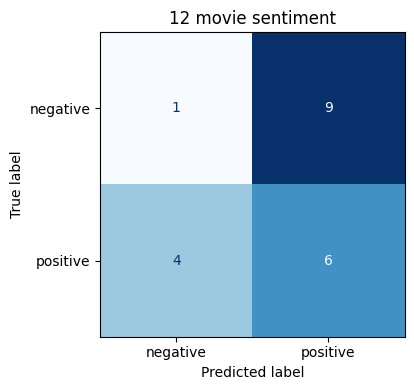

First five held-out predictions: ['negative' 'positive' 'positive' 'positive' 'positive']
New review predictions: ['positive' 'negative']


In [ ]:
df = pd.read_csv(DATA / 'reviews.csv')
X, y = df.text.map(clean_text), df.label
assert not X.duplicated().any()
stop_words = sorted(set(ENGLISH_STOP_WORDS) - {'not', 'no', 'nor', 'never'})
vectorizer = CountVectorizer(stop_words=stop_words, ngram_range=(1, 2))
print('Example tokens:', vectorizer.build_analyzer()(clean_text(X.iloc[0])))
model = make_pipeline(vectorizer, LinearSVC(C=1.0, random_state=SEED))
metrics = evaluate(model, X, y, '12_movie_sentiment')
examples = ['A wonderful story and excellent acting',
            'A boring story with terrible acting']
print('New review predictions:', model.predict([clean_text(s) for s in examples]))

### Result and conclusion
Measured results: accuracy = 0.3500; macro_f1 = 0.3067; baseline_accuracy = 0.5000. Accuracy is below the 0.50 majority baseline on this split. The small corpus is insufficient for reliable sentiment learning; use a larger independent review dataset before drawing performance conclusions.

## Practical 13: Dimensionality Reduction of Handwritten Digits

### Aim
Reduce handwritten-digit image features while retaining information and visualize samples in two dimensions.

### Model
Principal Component Analysis (PCA)

### Data
scikit-learn Digits benchmark: 1,797 images, each 8 x 8 pixels with intensities from 0 to 16.

### Theory
PCA finds orthogonal directions of maximum variance. A 95-percent-variance representation is compared with a separate two-component visualization. PCA is fitted only on training images; labels are used only to colour the held-out plot.

### Method
Load or generate data, inspect features and labels, fit preprocessing on training data, train the required model, evaluate and visualize the output. See the implementation for the task-specific split.

### Limitation
Two principal components retain much less information than the 95-percent representation; class overlap in two dimensions is expected.

In [ ]:
"""Shared imports and evaluation; also embedded in every standalone notebook."""
import re
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split
from sklearn.pipeline import make_pipeline
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.impute import SimpleImputer
from sklearn.linear_model import LinearRegression, LogisticRegression
from sklearn.neighbors import KNeighborsClassifier
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import (RandomForestClassifier, RandomForestRegressor,
    IsolationForest, GradientBoostingRegressor, AdaBoostRegressor)
from sklearn.svm import SVC, LinearSVC
from sklearn.naive_bayes import MultinomialNB
from sklearn.feature_extraction.text import (TfidfVectorizer,
    CountVectorizer, ENGLISH_STOP_WORDS)
from sklearn.cluster import KMeans
from sklearn.decomposition import PCA
from sklearn.datasets import load_iris, load_breast_cancer, load_digits
from sklearn.dummy import DummyClassifier, DummyRegressor
from sklearn.metrics import (accuracy_score, f1_score, classification_report,
    ConfusionMatrixDisplay, mean_absolute_error, mean_squared_error,
    r2_score, silhouette_score, average_precision_score)
SEED = 42
rng = np.random.default_rng(SEED)
OUT = Path('outputs')
OUT.mkdir(exist_ok=True)
plt.rcParams.update({'figure.figsize': (7, 4), 'font.size': 10})

def plot_save(name):
    plt.tight_layout()
    plt.savefig(OUT / f'{name}.png', dpi=150, bbox_inches='tight')
    plt.show()
    plt.close()

def tabular_preprocessor(frame):
    numeric = frame.select_dtypes(include='number').columns.tolist()
    category = frame.select_dtypes(exclude='number').columns.tolist()
    return ColumnTransformer([
        ('numeric', make_pipeline(SimpleImputer(strategy='median'),
                                  StandardScaler()), numeric),
        ('category', make_pipeline(SimpleImputer(strategy='most_frequent'),
          OneHotEncoder(handle_unknown='ignore', sparse_output=False)), category)])

def evaluate(model, X, y, name, classification=True, chronological=False):
    # All fitted preprocessing stays inside the model pipeline.
    Xtr, Xte, ytr, yte = train_test_split(X, y, test_size=0.25,
        random_state=None if chronological else SEED,
        shuffle=not chronological,
        stratify=y if classification and not chronological else None)
    model.fit(Xtr, ytr)
    pred = model.predict(Xte)
    print(f'Train: {len(ytr)} | Test: {len(yte)} | Features: '
          f'{X.shape[1] if hasattr(X, "shape") and len(X.shape)>1 else "text"}')
    if classification:
        baseline = DummyClassifier(strategy='most_frequent').fit(Xtr, ytr)
        metrics = {'accuracy': accuracy_score(yte, pred),
                   'macro_f1': f1_score(yte, pred, average='macro'),
                   'baseline_accuracy': accuracy_score(yte, baseline.predict(Xte))}
        print(classification_report(yte, pred, digits=3, zero_division=0))
        ConfusionMatrixDisplay.from_predictions(yte, pred, cmap='Blues',
                                                colorbar=False)
        plt.title(name.replace('_', ' '))
        if any(len(str(v)) > 8 for v in np.unique(yte)):
            plt.xticks(rotation=30, ha='right')
    else:
        baseline = DummyRegressor().fit(Xtr, ytr)
        metrics = {'MAE': mean_absolute_error(yte, pred),
                   'RMSE': np.sqrt(mean_squared_error(yte, pred)),
                   'R2': r2_score(yte, pred),
                   'baseline_MAE': mean_absolute_error(yte, baseline.predict(Xte))}
        plt.scatter(yte, pred, alpha=0.6, s=18)
        lo, hi = min(min(yte), min(pred)), max(max(yte), max(pred))
        plt.plot([lo, hi], [lo, hi], 'k--')
        plt.xlabel('Actual target'); plt.ylabel('Predicted target')
        plt.title(name.replace('_', ' '))
    for key, value in metrics.items():
        print(f'{key}: {value:.4f}')
    plot_save(name)
    print('First five held-out predictions:', pred[:5])
    return metrics

def clean_text(text):
    text = re.sub(r'https?://\S+', ' url ', str(text).lower())
    text = re.sub(r'\d+', ' number ', text)
    return ' '.join(re.findall(r'[a-z]+', text))


In [ ]:
DATA = Path('data')
DATA.mkdir(exist_ok=True)


Train: 1347 | Test: 450 | Original features: 64
components_for_95pct: 29.0000
retained_variance: 0.9549
two_dimensional_variance: 0.2842
test_reconstruction_MSE: 0.0035


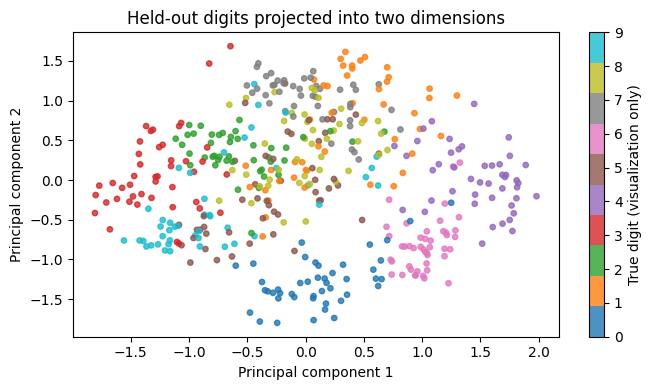

In [ ]:
dataset = load_digits()
X, y = dataset.data / 16.0, dataset.target
Xtr, Xte, ytr, yte = train_test_split(X, y, test_size=0.25,
                                    stratify=y, random_state=SEED)
pca95 = PCA(n_components=0.95, svd_solver='full').fit(Xtr)
compressed = pca95.transform(Xte)
reconstructed = pca95.inverse_transform(compressed)
pca2 = PCA(n_components=2, svd_solver='full').fit(Xtr)
points = pca2.transform(Xte)
metrics = {'components_for_95pct': pca95.n_components_,
    'retained_variance': pca95.explained_variance_ratio_.sum(),
    'two_dimensional_variance': pca2.explained_variance_ratio_.sum(),
    'test_reconstruction_MSE': mean_squared_error(Xte, reconstructed)}
print(f'Train: {len(Xtr)} | Test: {len(Xte)} | Original features: 64')
for key, value in metrics.items(): print(f'{key}: {value:.4f}')
plt.scatter(points[:, 0], points[:, 1], c=yte, cmap='tab10', s=15, alpha=0.8)
plt.colorbar(ticks=range(10), label='True digit (visualization only)')
plt.xlabel('Principal component 1'); plt.ylabel('Principal component 2')
plt.title('Held-out digits projected into two dimensions')
plot_save('13_digits_pca')

### Result and conclusion
Measured results: components_for_95pct = 29.0000; retained_variance = 0.9549; two_dimensional_variance = 0.2842; test_reconstruction_MSE = 0.0035. Two principal components retain much less information than the 95-percent representation; class overlap in two dimensions is expected.

## Practical 14: News Category Prediction

### Aim
Classify headlines into Sports, Business, Technology, Politics and Entertainment.

### Model
TF-IDF + Multinomial Logistic Regression

### Data
100 original teaching headlines: 20 per category, with no downloaded news text. Each headline is unique.

### Theory
TF-IDF represents unigram and bigram evidence. Logistic regression with the lbfgs solver optimizes multinomial softmax loss for the five-class task.

### Method
Load or generate data, inspect features and labels, fit preprocessing on training data, train the required model, evaluate and visualize the output. See the implementation for the task-specific split.

### Limitation
Topic keywords are comparatively clear in this teaching corpus; production news can span multiple categories or change vocabulary.

In [ ]:
"""Shared imports and evaluation; also embedded in every standalone notebook."""
import re
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split
from sklearn.pipeline import make_pipeline
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.impute import SimpleImputer
from sklearn.linear_model import LinearRegression, LogisticRegression
from sklearn.neighbors import KNeighborsClassifier
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import (RandomForestClassifier, RandomForestRegressor,
    IsolationForest, GradientBoostingRegressor, AdaBoostRegressor)
from sklearn.svm import SVC, LinearSVC
from sklearn.naive_bayes import MultinomialNB
from sklearn.feature_extraction.text import (TfidfVectorizer,
    CountVectorizer, ENGLISH_STOP_WORDS)
from sklearn.cluster import KMeans
from sklearn.decomposition import PCA
from sklearn.datasets import load_iris, load_breast_cancer, load_digits
from sklearn.dummy import DummyClassifier, DummyRegressor
from sklearn.metrics import (accuracy_score, f1_score, classification_report,
    ConfusionMatrixDisplay, mean_absolute_error, mean_squared_error,
    r2_score, silhouette_score, average_precision_score)
SEED = 42
rng = np.random.default_rng(SEED)
OUT = Path('outputs')
OUT.mkdir(exist_ok=True)
plt.rcParams.update({'figure.figsize': (7, 4), 'font.size': 10})

def plot_save(name):
    plt.tight_layout()
    plt.savefig(OUT / f'{name}.png', dpi=150, bbox_inches='tight')
    plt.show()
    plt.close()

def tabular_preprocessor(frame):
    numeric = frame.select_dtypes(include='number').columns.tolist()
    category = frame.select_dtypes(exclude='number').columns.tolist()
    return ColumnTransformer([
        ('numeric', make_pipeline(SimpleImputer(strategy='median'),
                                  StandardScaler()), numeric),
        ('category', make_pipeline(SimpleImputer(strategy='most_frequent'),
          OneHotEncoder(handle_unknown='ignore', sparse_output=False)), category)])

def evaluate(model, X, y, name, classification=True, chronological=False):
    # All fitted preprocessing stays inside the model pipeline.
    Xtr, Xte, ytr, yte = train_test_split(X, y, test_size=0.25,
        random_state=None if chronological else SEED,
        shuffle=not chronological,
        stratify=y if classification and not chronological else None)
    model.fit(Xtr, ytr)
    pred = model.predict(Xte)
    print(f'Train: {len(ytr)} | Test: {len(yte)} | Features: '
          f'{X.shape[1] if hasattr(X, "shape") and len(X.shape)>1 else "text"}')
    if classification:
        baseline = DummyClassifier(strategy='most_frequent').fit(Xtr, ytr)
        metrics = {'accuracy': accuracy_score(yte, pred),
                   'macro_f1': f1_score(yte, pred, average='macro'),
                   'baseline_accuracy': accuracy_score(yte, baseline.predict(Xte))}
        print(classification_report(yte, pred, digits=3, zero_division=0))
        ConfusionMatrixDisplay.from_predictions(yte, pred, cmap='Blues',
                                                colorbar=False)
        plt.title(name.replace('_', ' '))
        if any(len(str(v)) > 8 for v in np.unique(yte)):
            plt.xticks(rotation=30, ha='right')
    else:
        baseline = DummyRegressor().fit(Xtr, ytr)
        metrics = {'MAE': mean_absolute_error(yte, pred),
                   'RMSE': np.sqrt(mean_squared_error(yte, pred)),
                   'R2': r2_score(yte, pred),
                   'baseline_MAE': mean_absolute_error(yte, baseline.predict(Xte))}
        plt.scatter(yte, pred, alpha=0.6, s=18)
        lo, hi = min(min(yte), min(pred)), max(max(yte), max(pred))
        plt.plot([lo, hi], [lo, hi], 'k--')
        plt.xlabel('Actual target'); plt.ylabel('Predicted target')
        plt.title(name.replace('_', ' '))
    for key, value in metrics.items():
        print(f'{key}: {value:.4f}')
    plot_save(name)
    print('First five held-out predictions:', pred[:5])
    return metrics

def clean_text(text):
    text = re.sub(r'https?://\S+', ' url ', str(text).lower())
    text = re.sub(r'\d+', ' number ', text)
    return ' '.join(re.findall(r'[a-z]+', text))


In [ ]:
DATA = Path('data')
DATA.mkdir(exist_ok=True)
(DATA / 'news.csv').write_text('text,label\nFootball team wins championship after dramatic final,Sports\nCricket captain scores century in tournament victory,Sports\nTennis star reaches final after thrilling match,Sports\nOlympic runner sets record in sprint race,Sports\nBasketball team signs experienced coach for season,Sports\nHockey players prepare for international tournament,Sports\nFootball club announces new stadium training facilities,Sports\nSwimmer wins gold medal at national championships,Sports\nCricket league introduces revised match schedule,Sports\nTennis champion returns after injury recovery,Sports\nAthletics federation selects squad for world games,Sports\nBaseball team celebrates playoff victory at home,Sports\nCyclist takes lead in mountain stage race,Sports\nBadminton player wins first international title,Sports\nRugby squad prepares for difficult away match,Sports\nFootball goalkeeper saves penalty in cup final,Sports\nMarathon runners gather for annual city race,Sports\nVolleyball team secures place in regional finals,Sports\nBoxing champion defends title in close contest,Sports\nSports academy launches training camp for young athletes,Sports\nStock market rises as company profits beat forecasts,Business\nBank announces lower interest rates for business loans,Business\nRetail company reports strong quarterly sales growth,Business\nInvestors welcome merger between major financial firms,Business\nOil prices fall amid concerns about global demand,Business\nStartup raises funding to expand its operations,Business\nCentral bank reviews inflation and monetary policy,Business\nManufacturing company opens factory creating new jobs,Business\nCurrency markets react to economic growth figures,Business\nExport businesses seek relief from rising costs,Business\nShareholders approve new corporate investment plan,Business\nBanking sector reports increase in digital payments,Business\nRetail chain expands stores ahead of festive season,Business\nInsurance company announces improved annual earnings,Business\nInvestors shift funds as bond yields increase,Business\nSmall businesses report recovery in customer demand,Business\nTrade agreement aims to boost exports and investment,Business\nCompany shares decline after disappointing revenue report,Business\nEconomic survey shows growth in service industries,Business\nFinance ministry discusses tax incentives for businesses,Business\nSoftware company launches new artificial intelligence tool,Technology\nResearchers develop faster computer chip for mobile devices,Technology\nCybersecurity experts discover flaw in popular software,Technology\nNew smartphone offers improved battery and camera,Technology\nCloud computing platform adds data protection features,Technology\nScientists test robot designed for underwater exploration,Technology\nTechnology startup builds accessible virtual reality headset,Technology\nNew programming framework simplifies web application development,Technology\nArtificial intelligence system improves speech recognition accuracy,Technology\nSpace agency tests communication technology for satellites,Technology\nComputer engineers develop energy efficient processors,Technology\nSoftware update fixes security issues in messaging app,Technology\nResearchers demonstrate advances in quantum computing hardware,Technology\nNew wearable device monitors fitness with smart sensors,Technology\nInternet provider expands high speed fibre network,Technology\nRobotics team unveils automated warehouse machine,Technology\nTechnology firm releases open source machine learning library,Technology\nSmartphone manufacturer introduces foldable display design,Technology\nCybersecurity conference focuses on protecting digital identities,Technology\nDevelopers create software to detect manipulated images,Technology\nParliament debates new education bill during winter session,Politics\nGovernment announces reforms after cabinet meeting,Politics\nElection commission publishes schedule for national polls,Politics\nOpposition leaders demand debate on public spending,Politics\nPresident meets foreign minister for diplomatic talks,Politics\nVoters head to polls in closely contested election,Politics\nPolitical parties negotiate coalition after election results,Politics\nCabinet approves proposal for local government reform,Politics\nLawmakers question minister during parliamentary session,Politics\nGovernment introduces legislation on public administration,Politics\nPrime minister addresses nation on policy priorities,Politics\nElection campaign focuses on jobs and public services,Politics\nParliamentary committee reviews proposed constitutional amendment,Politics\nDiplomatic delegation discusses regional peace agreement,Politics\nOpposition party announces candidates for upcoming election,Politics\nState government presents new transport policy in assembly,Politics\nLawmakers vote on reforms after lengthy debate,Politics\nPolitical leaders attend summit on international cooperation,Politics\nElection officials announce updated voter registration rules,Politics\nCabinet minister resigns following parliamentary inquiry,Politics\nFilm festival opens with premiere of acclaimed drama,Entertainment\nActor announces new movie with award winning director,Entertainment\nSinger releases album ahead of international concert tour,Entertainment\nTelevision series returns with new season and cast,Entertainment\nMusic awards celebrate outstanding performances of the year,Entertainment\nPopular actress stars in upcoming romantic comedy,Entertainment\nTheatre company stages classic play for summer season,Entertainment\nStreaming platform announces slate of original films,Entertainment\nFans welcome musician at sold out concert venue,Entertainment\nAnimated film tops weekend box office chart,Entertainment\nDirector discusses creative process at cinema festival,Entertainment\nCelebrity couple attends charity gala and film premiere,Entertainment\nNew documentary explores history of popular music,Entertainment\nComedy show brings famous performers to city theatre,Entertainment\nActor wins award for leading role in historical film,Entertainment\nDance festival features performances from international artists,Entertainment\nMovie studio releases trailer for fantasy adventure,Entertainment\nSinger announces acoustic concerts across major cities,Entertainment\nTelevision drama receives praise for ensemble cast,Entertainment\nEntertainment awards honour veteran filmmaker and musicians,Entertainment\n', encoding='utf-8')


6404

Headlines: 100 | Categories: ['Business', 'Entertainment', 'Politics', 'Sports', 'Technology']
Train: 75 | Test: 25 | Features: text
               precision    recall  f1-score   support

     Business      0.600     0.600     0.600         5
Entertainment      0.500     0.800     0.615         5
     Politics      0.833     1.000     0.909         5
       Sports      0.833     1.000     0.909         5
   Technology      0.000     0.000     0.000         5

     accuracy                          0.680        25
    macro avg      0.553     0.680     0.607        25
 weighted avg      0.553     0.680     0.607        25

accuracy: 0.6800
macro_f1: 0.6067
baseline_accuracy: 0.2000


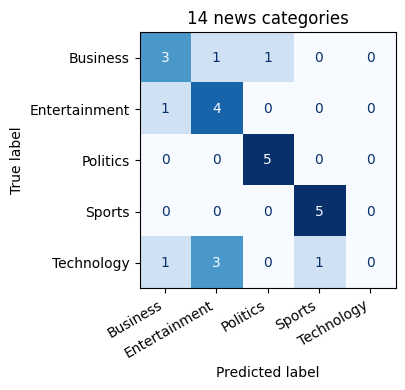

First five held-out predictions: ['Sports' 'Sports' 'Politics' 'Entertainment' 'Business']
New headline predictions: ['Sports' 'Technology']


In [ ]:
df = pd.read_csv(DATA / 'news.csv')
X, y = df.text.map(clean_text), df.label
assert not X.duplicated().any()
print('Headlines:', len(df), '| Categories:', sorted(y.unique()))
model = make_pipeline(TfidfVectorizer(ngram_range=(1, 2)),
    LogisticRegression(solver='lbfgs', max_iter=2000, random_state=SEED))
metrics = evaluate(model, X, y, '14_news_categories')
examples = ['Team wins the football tournament final',
            'Software company releases a new artificial intelligence chip']
print('New headline predictions:', model.predict([clean_text(s) for s in examples]))

### Result and conclusion
Measured results: accuracy = 0.6800; macro_f1 = 0.6067; baseline_accuracy = 0.2000. Topic keywords are comparatively clear in this teaching corpus; production news can span multiple categories or change vocabulary.

## Practical 15: Sales Prediction

### Aim
Predict future sales from advertising, previous sales, product price, discounts and seasonal features.

### Model
AdaBoost Regressor

### Data
600 generated daily observations; sales are units, advertising and price are currency units, discount is a fraction. The final 150 days form the test period.

### Theory
AdaBoost combines weak regression trees while increasing attention to poorly predicted observations. Evaluation uses a chronological split; previous-day sales are observable for rolling one-day-ahead prediction.

### Method
Load or generate data, inspect features and labels, fit preprocessing on training data, train the required model, evaluate and visualize the output. See the implementation for the task-specific split.

### Limitation
This is rolling one-day-ahead forecasting with known advertising and price. Multi-day forecasting would need predicted lags and a separate evaluation.

In [ ]:
"""Shared imports and evaluation; also embedded in every standalone notebook."""
import re
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split
from sklearn.pipeline import make_pipeline
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.impute import SimpleImputer
from sklearn.linear_model import LinearRegression, LogisticRegression
from sklearn.neighbors import KNeighborsClassifier
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import (RandomForestClassifier, RandomForestRegressor,
    IsolationForest, GradientBoostingRegressor, AdaBoostRegressor)
from sklearn.svm import SVC, LinearSVC
from sklearn.naive_bayes import MultinomialNB
from sklearn.feature_extraction.text import (TfidfVectorizer,
    CountVectorizer, ENGLISH_STOP_WORDS)
from sklearn.cluster import KMeans
from sklearn.decomposition import PCA
from sklearn.datasets import load_iris, load_breast_cancer, load_digits
from sklearn.dummy import DummyClassifier, DummyRegressor
from sklearn.metrics import (accuracy_score, f1_score, classification_report,
    ConfusionMatrixDisplay, mean_absolute_error, mean_squared_error,
    r2_score, silhouette_score, average_precision_score)
SEED = 42
rng = np.random.default_rng(SEED)
OUT = Path('outputs')
OUT.mkdir(exist_ok=True)
plt.rcParams.update({'figure.figsize': (7, 4), 'font.size': 10})

def plot_save(name):
    plt.tight_layout()
    plt.savefig(OUT / f'{name}.png', dpi=150, bbox_inches='tight')
    plt.show()
    plt.close()

def tabular_preprocessor(frame):
    numeric = frame.select_dtypes(include='number').columns.tolist()
    category = frame.select_dtypes(exclude='number').columns.tolist()
    return ColumnTransformer([
        ('numeric', make_pipeline(SimpleImputer(strategy='median'),
                                  StandardScaler()), numeric),
        ('category', make_pipeline(SimpleImputer(strategy='most_frequent'),
          OneHotEncoder(handle_unknown='ignore', sparse_output=False)), category)])

def evaluate(model, X, y, name, classification=True, chronological=False):
    # All fitted preprocessing stays inside the model pipeline.
    Xtr, Xte, ytr, yte = train_test_split(X, y, test_size=0.25,
        random_state=None if chronological else SEED,
        shuffle=not chronological,
        stratify=y if classification and not chronological else None)
    model.fit(Xtr, ytr)
    pred = model.predict(Xte)
    print(f'Train: {len(ytr)} | Test: {len(yte)} | Features: '
          f'{X.shape[1] if hasattr(X, "shape") and len(X.shape)>1 else "text"}')
    if classification:
        baseline = DummyClassifier(strategy='most_frequent').fit(Xtr, ytr)
        metrics = {'accuracy': accuracy_score(yte, pred),
                   'macro_f1': f1_score(yte, pred, average='macro'),
                   'baseline_accuracy': accuracy_score(yte, baseline.predict(Xte))}
        print(classification_report(yte, pred, digits=3, zero_division=0))
        ConfusionMatrixDisplay.from_predictions(yte, pred, cmap='Blues',
                                                colorbar=False)
        plt.title(name.replace('_', ' '))
        if any(len(str(v)) > 8 for v in np.unique(yte)):
            plt.xticks(rotation=30, ha='right')
    else:
        baseline = DummyRegressor().fit(Xtr, ytr)
        metrics = {'MAE': mean_absolute_error(yte, pred),
                   'RMSE': np.sqrt(mean_squared_error(yte, pred)),
                   'R2': r2_score(yte, pred),
                   'baseline_MAE': mean_absolute_error(yte, baseline.predict(Xte))}
        plt.scatter(yte, pred, alpha=0.6, s=18)
        lo, hi = min(min(yte), min(pred)), max(max(yte), max(pred))
        plt.plot([lo, hi], [lo, hi], 'k--')
        plt.xlabel('Actual target'); plt.ylabel('Predicted target')
        plt.title(name.replace('_', ' '))
    for key, value in metrics.items():
        print(f'{key}: {value:.4f}')
    plot_save(name)
    print('First five held-out predictions:', pred[:5])
    return metrics

def clean_text(text):
    text = re.sub(r'https?://\S+', ' url ', str(text).lower())
    text = re.sub(r'\d+', ' number ', text)
    return ' '.join(re.findall(r'[a-z]+', text))


In [ ]:
DATA = Path('data')
DATA.mkdir(exist_ok=True)


Train: 450 | Test: 150 | Features: 5
MAE: 15.0879
RMSE: 18.8174
R2: 0.7808
baseline_MAE: 32.2104


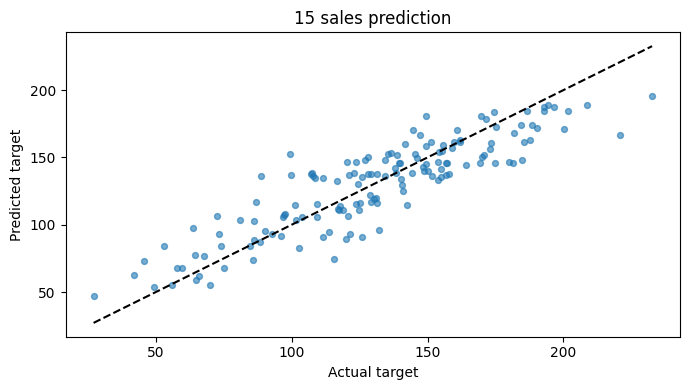

First five held-out predictions: [136.88515544 184.27396775 135.89506068 105.6832726   87.55266437]
Previous-day persistence MAE: 29.1514


In [ ]:
n = 601
advertising = rng.uniform(10, 100, n)
price = rng.uniform(15, 40, n)
discount = rng.uniform(0, 0.3, n)
season = np.sin(2*np.pi*np.arange(n)/30)
sales = np.zeros(n); sales[0] = 100
for t in range(1, n):
    sales[t] = max(0, 30 + 0.45*sales[t-1] + 1.2*advertising[t]
        - 1.3*price[t] + 80*discount[t] + 15*season[t]
        + rng.normal(0, 8))
X = pd.DataFrame({'advertising': advertising[1:],
    'previous_sales': sales[:-1], 'price': price[1:],
    'discount': discount[1:], 'seasonal_signal': season[1:]})
y = sales[1:]
model = AdaBoostRegressor(n_estimators=150, learning_rate=0.05,
                          loss='square', random_state=SEED)
metrics = evaluate(model, X, y, '15_sales_prediction',
                   classification=False, chronological=True)
cut = int(len(y)*0.75)
metrics['persistence_MAE'] = mean_absolute_error(y[cut:], X.previous_sales.iloc[cut:])
print(f'Previous-day persistence MAE: {metrics["persistence_MAE"]:.4f}')

### Result and conclusion
Measured results: MAE = 15.0667; RMSE = 18.9475; R2 = 0.7778; baseline_MAE = 32.2104; persistence_MAE = 29.1514. This is rolling one-day-ahead forecasting with known advertising and price. Multi-day forecasting would need predicted lags and a separate evaluation.

In [ ]:
print('ALL 15 PRACTICALS COMPLETED SUCCESSFULLY')

ALL 15 PRACTICALS COMPLETED SUCCESSFULLY
